# Lululime — Should leadership scrap repairs and expand loyalty?
Dataverse 2026 · Final notebook. Every output below is saved, so it can be read without running anything.

**How to run it yourself.** This notebook is self-contained: every cleaning rule, table and model is defined in the
cells below. It needs only:
1. **The three case CSVs:** `sales.csv`, `items.csv` and `customers.csv`, in the same folder as this notebook
   (a `data/raw/` or `data/` subfolder also works, or set `DATA_DIR` in the setup cell).
2. **Python 3.10+ with:** pandas, numpy, matplotlib, scikit-learn and scipy. If any are missing, run
   `pip install pandas numpy matplotlib scikit-learn scipy` first.

Then **Run All** (about 6–7 minutes; the churn-model bootstrap in section 6 takes about two of them). Results are
deterministic (fixed random seeds), so a re-run reproduces every number in the deck.

## 0. Setup: packages, data location and shared definitions
All dates, thresholds and business rules used anywhere in the notebook are set once here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

# Where the three case CSVs are: the first folder below that contains sales.csv is used.
DATA_DIR = next((d for d in [Path("."), Path("data/raw"), Path("data")] if (d / "sales.csv").exists()), None)
assert DATA_DIR is not None, ("Put sales.csv, items.csv and customers.csv next to this notebook "
                              "(or in data/raw/), or set DATA_DIR to their folder.")
print(f"Reading the case data from: {DATA_DIR.as_posix()}/ (relative to this notebook)")


class C:
    """Shared definitions: data window, key dates, loyalty rules, profit rules, customer definitions."""
    SALES_CSV, ITEMS_CSV, CUSTOMERS_CSV = DATA_DIR / "sales.csv", DATA_DIR / "items.csv", DATA_DIR / "customers.csv"

    # Data window
    DATA_START = pd.Timestamp("2022-11-01")    # first sales row
    DATA_END = pd.Timestamp("2026-10-31")      # last sales row
    AS_OF_DATE = DATA_END                      # "today" for churn and trailing-12-month metrics

    # Key dates
    COMPETITOR_OPEN_DAY = pd.Timestamp("2024-03-15")   # the opening day (day-level work and charts)
    COMPETITOR_OPEN = pd.Timestamp("2024-03-01")       # the month it opened (monthly analysis)
    LOYALTY_LAUNCH = pd.Timestamp("2024-06-01")
    PILATES_START = pd.Timestamp("2025-01-06")
    PILATES_END = pd.Timestamp("2025-03-31")
    REPAIRS_LAUNCH = pd.Timestamp("2025-04-01")
    WEBSITE_LAUNCH = pd.Timestamp("2025-11-17")
    NEW_MANAGER = pd.Timestamp("2026-02-02")
    EVENTS = {"competitor_open": COMPETITOR_OPEN_DAY, "loyalty_launch": LOYALTY_LAUNCH,
              "pilates_start": PILATES_START, "pilates_end": PILATES_END, "repairs_launch": REPAIRS_LAUNCH,
              "website_launch": WEBSITE_LAUNCH, "new_manager": NEW_MANAGER}

    # Loyalty
    POINTS_PER_DOLLAR_REDEEMED = 20            # 20 points = $1 off
    SILVER_THRESHOLD, GOLD_THRESHOLD = 600, 2000   # points earned in the trailing 365 days
    TIER_WINDOW_DAYS = 365
    PRE_LOYALTY = "Pre-loyalty"                # blank tier before the loyalty launch
    TIER_ORDER = [PRE_LOYALTY, "Non-member", "Member", "Silver", "Gold"]
    TIER_RANK = {t: i for i, t in enumerate(TIER_ORDER)}

    # Profit = revenue − production cost − repair cost − redeemed points ($)
    RETURN_COST_REVERSES = True                # a returned item's production cost is reversed with its revenue
    REPAIR_ITEMS = {"R01": "outerwear", "R02": "activewear"}   # cost $45 / $18, price $0

    # Customer definitions
    CHURN_DAYS = 180                           # churned = no visit in the last 180 days
    ARR_WINDOW_MONTHS = 12                     # ARR = repeat-customer revenue over the trailing 12 months

    # Row types and interests
    PURCHASE, RETURN, DROPOFF, PICKUP = "Purchase", "Return", "Repair Drop-off", "Repair Pickup"
    INTERESTS = ["Run", "Yoga", "Pilates", "Outdoor", "Lifestyle"]


# Shared chart style (validated palette: blue / orange; recessive grid)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "lines.linewidth": 2,
})
EVENT_LABELS = {
    "competitor_open": "Competitor opens", "loyalty_launch": "Loyalty launch",
    "pilates_start": "Pilates push", "repairs_launch": "Free repairs",
    "website_launch": "Website", "new_manager": "New manager",
}


def mark_events(ax, ymax):
    """Dashed vertical line and label for each initiative."""
    for i, (key, label) in enumerate(EVENT_LABELS.items()):
        d = C.EVENTS[key]
        ax.axvline(d, color=INK2, lw=0.8, ls=(0, (3, 3)), zorder=1)
        ax.text(d, ymax * (0.995 - 0.035 * (i % 2)), " " + label, color=INK2, fontsize=9, va="top")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 5, 9]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

Reading the case data from: data/raw/ (relative to this notebook)


## 1. Problem framing
A competitor opened across the street in **March 2024** and targeted younger customers with lower prices.
Lululime responded with a loyalty program (Jun 2024), a Pilates campaign (Jan–Mar 2025) and free repairs (Apr 2025).
Revenue has since recovered. Leadership credits loyalty and plans to **expand loyalty perks and shut down free repairs**,
believing repairs only cost money and cannibalize outerwear sales.

We test that plan through two numbers:
- **ARR:** revenue from repeat customers (any visit after their signup date) over the trailing 12 months.
- **Profit:** revenue − production costs − repair costs − redeemed points ($1 per 20 points).

## 2. Data & methodology
Every cleaning and joining step is defined below and run from the raw CSVs:
1. **Clean:** read IDs as text; drop exact duplicate sales rows (1,016); blank tier before the loyalty launch =
   "Pre-loyalty" (not "Non-member"); blank points = 0; split customer interests into yes/no columns.
2. **Join:** sales → items on `item_id`, → customers on `customer_id` (left joins, checked many-to-one). One row per
   sales line.
3. **Profit per line:** revenue = quantity × price paid (returns are negative); production cost on purchases and
   returns; repair cost at **drop-off only** (pickups cost $0, unpicked drop-offs still count); redeemed points at
   $1 per 20 points.
4. **Tables:** visits (one row per transaction; `points_redeemed` summed per transaction, `points_balance_after`
   never summed), customers (churn, ARR, repair use), customer-months (rolling 12-month ARR), and links (returns →
   purchases and repair pickups → drop-offs, matched on `original_transaction_id` + `item_id`).

The integrity checks print below; every one must pass.

In [2]:
ID_COLS = {"transaction_id": str, "customer_id": str, "item_id": str, "original_transaction_id": str}


def read_raw():
    """Read the raw CSVs with IDs as text. No cleaning."""
    sales = pd.read_csv(C.SALES_CSV, dtype={**ID_COLS, "tier_at_purchase": str, "notes": str})
    items = pd.read_csv(C.ITEMS_CSV, dtype={"item_id": str})
    customers = pd.read_csv(C.CUSTOMERS_CSV, dtype={"customer_id": str})
    return sales, items, customers


def clean_sales(sales):
    s = sales.drop_duplicates(keep="first").copy()            # exact double entries
    s["date"] = pd.to_datetime(s["date"])
    s["datetime"] = pd.to_datetime(s["date"].dt.strftime("%Y-%m-%d") + " " + s["time"])
    pre = s["date"] < C.LOYALTY_LAUNCH                        # blank tier before launch = Pre-loyalty
    s.loc[pre & s["tier_at_purchase"].isna(), "tier_at_purchase"] = C.PRE_LOYALTY
    assert s["tier_at_purchase"].notna().all(), "blank tier after loyalty launch"
    for col in ["points_earned", "points_redeemed", "points_balance_after"]:
        s[col] = s[col].fillna(0)                             # blank points = 0
    notes = s["notes"].str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    s["notes"] = notes.mask(notes == "")
    return s


def clean_customers(customers):
    c = customers.copy()
    c["signup_date"] = pd.to_datetime(c["signup_date"])
    c["loyalty_join_date"] = pd.to_datetime(c["loyalty_join_date"])
    c["age_band"] = c["age_band"].fillna("Unknown")
    c["home_area"] = c["home_area"].fillna("Unknown")
    split = c["interests"].fillna("").str.split(";")
    for name in C.INTERESTS:
        c[f"interest_{name.lower()}"] = split.apply(lambda xs, n=name: int(n in xs))
    c["is_member"] = c["loyalty_join_date"].notna()
    return c


def build_lines(sales, items, customers):
    """sales LEFT JOIN items LEFT JOIN customers (many-to-one), plus revenue, costs and profit per line."""
    df = sales.merge(items, on="item_id", how="left", validate="many_to_one")
    df = df.merge(customers, on="customer_id", how="left", validate="many_to_one")
    rt = df["row_type"]
    df["revenue"] = df["quantity"] * df["unit_price_paid"]                 # returns are negative
    prod = df["quantity"] * df["production_cost"]
    if not C.RETURN_COST_REVERSES:
        prod = prod.where(rt != C.RETURN, 0.0)
    df["production_cost_amt"] = prod.where(rt.isin([C.PURCHASE, C.RETURN]), 0.0)
    df["repair_cost_amt"] = (df["quantity"] * df["production_cost"]).where(rt == C.DROPOFF, 0.0)   # drop-off only
    df["redeemed_dollars"] = df["points_redeemed"] / C.POINTS_PER_DOLLAR_REDEEMED
    df["profit"] = df["revenue"] - df["production_cost_amt"] - df["repair_cost_amt"] - df["redeemed_dollars"]
    df["is_repeat_visit"] = df["date"] > df["signup_date"]
    df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
    return df


def build_visits(lines):
    """One row per transaction."""
    v = lines.groupby("transaction_id", sort=False).agg(
        customer_id=("customer_id", "first"), datetime=("datetime", "first"), date=("date", "first"),
        month=("month", "first"), signup_date=("signup_date", "first"), tier=("tier_at_purchase", "first"),
        n_lines=("item_id", "size"), units=("quantity", "sum"), revenue=("revenue", "sum"),
        production_cost=("production_cost_amt", "sum"), repair_cost=("repair_cost_amt", "sum"),
        points_earned=("points_earned", "sum"),
        points_redeemed=("points_redeemed", "sum"),                 # summed per transaction
        points_balance_after=("points_balance_after", "first"),     # never summed
        redeemed_dollars=("redeemed_dollars", "sum"), profit=("profit", "sum"),
    ).reset_index()
    for rt, col in [(C.PURCHASE, "has_purchase"), (C.RETURN, "has_return"),
                    (C.DROPOFF, "has_dropoff"), (C.PICKUP, "has_pickup")]:
        v[col] = v["transaction_id"].isin(lines.loc[lines["row_type"] == rt, "transaction_id"])
    v["is_repeat_visit"] = v["date"] > v["signup_date"]
    return v.sort_values("datetime").reset_index(drop=True)


def build_customers(customers, visits):
    """One row per customer: visits, revenue, ARR, repair use, highest tier, churn."""
    since_12m = C.AS_OF_DATE - pd.DateOffset(months=C.ARR_WINDOW_MONTHS)
    v = visits.assign(
        rev_12m=visits["revenue"].where(visits["date"] > since_12m, 0.0),
        arr_12m=visits["revenue"].where((visits["date"] > since_12m) & visits["is_repeat_visit"], 0.0),
        tier_rank=visits["tier"].map(C.TIER_RANK))
    agg = v.groupby("customer_id").agg(
        first_visit=("date", "min"), last_visit=("date", "max"), n_visits=("transaction_id", "size"),
        n_repeat_visits=("is_repeat_visit", "sum"), revenue_total=("revenue", "sum"), profit_total=("profit", "sum"),
        revenue_12m=("rev_12m", "sum"), arr_12m=("arr_12m", "sum"), redeemed_dollars_total=("redeemed_dollars", "sum"),
        n_repair_dropoffs=("has_dropoff", "sum"), n_returns=("has_return", "sum"), max_tier_rank=("tier_rank", "max"))
    agg = agg.join(v[v["has_dropoff"]].groupby("customer_id")["date"].min().rename("first_repair_date"))
    agg["used_repair"] = agg["n_repair_dropoffs"] > 0
    agg["max_tier"] = agg["max_tier_rank"].map(dict(enumerate(C.TIER_ORDER)))
    agg = agg.drop(columns="max_tier_rank")
    agg["days_since_last_visit"] = (C.AS_OF_DATE - agg["last_visit"]).dt.days
    agg["churned"] = agg["days_since_last_visit"] > C.CHURN_DAYS
    out = customers.merge(agg, left_on="customer_id", right_index=True, how="left", validate="one_to_one")
    out["has_sales"] = out["n_visits"].notna()
    return out


def build_customer_month(visits):
    """One row per customer per month, from their first visit to the end of the data, with rolling 12-month ARR."""
    v = visits.assign(repeat_revenue=visits["revenue"].where(visits["is_repeat_visit"], 0.0))
    m = v.groupby(["customer_id", "month"]).agg(
        n_visits=("transaction_id", "size"), revenue=("revenue", "sum"), repeat_revenue=("repeat_revenue", "sum"),
        profit=("profit", "sum"), last_visit_in_month=("date", "max"))
    m = m.join(v.sort_values("datetime").groupby(["customer_id", "month"])["tier"].last().rename("tier_last_seen"))
    end = C.DATA_END.to_period("M").to_timestamp()
    first = v.groupby("customer_id")["month"].min()
    panel = pd.DataFrame({"customer_id": first.index,
                          "month": [pd.date_range(f, end, freq="MS") for f in first.values]}).explode("month")
    panel["month"] = pd.to_datetime(panel["month"])
    cm = panel.merge(m.reset_index(), on=["customer_id", "month"], how="left")
    cm = cm.sort_values(["customer_id", "month"]).reset_index(drop=True)
    for col in ["n_visits", "revenue", "repeat_revenue", "profit"]:
        cm[col] = cm[col].fillna(0)
    cm["n_visits"] = cm["n_visits"].astype(int)
    cm["active"] = cm["n_visits"] > 0
    grp = cm.groupby("customer_id", sort=False)
    cm["tier_last_seen"] = grp["tier_last_seen"].ffill()        # tier is only recorded at visits
    cm["arr_12m"] = (grp["repeat_revenue"].rolling(C.ARR_WINDOW_MONTHS, min_periods=1).sum()
                     .reset_index(level=0, drop=True))
    last_visit = grp["last_visit_in_month"].ffill()
    cm["days_since_last_visit"] = (cm["month"] + pd.offsets.MonthEnd(0) - last_visit).dt.days
    cm["churned"] = cm["days_since_last_visit"] > C.CHURN_DAYS
    return cm.drop(columns="last_visit_in_month")


def build_links(lines):
    """Returns → their purchase and repair pickups → their drop-off, matched on original_transaction_id + item_id."""
    cols = ["transaction_id", "item_id", "customer_id", "date", "row_type", "original_transaction_id",
            "unit_price_paid", "notes"]
    out = []
    for child, parent, kind in [(C.RETURN, C.PURCHASE, "return"), (C.PICKUP, C.DROPOFF, "repair")]:
        ch = lines.loc[lines["row_type"] == child, cols].copy()
        par = (lines.loc[lines["row_type"] == parent, ["transaction_id", "item_id", "date"]]
               .drop_duplicates(["transaction_id", "item_id"])
               .rename(columns={"transaction_id": "original_transaction_id", "date": "original_date"}))
        ch = ch.merge(par, on=["original_transaction_id", "item_id"], how="left", validate="many_to_one")
        ch["link_type"] = kind
        out.append(ch)
    links = pd.concat(out, ignore_index=True)
    links["resolved"] = links["original_date"].notna()
    links["days_between"] = (links["date"] - links["original_date"]).dt.days
    return links


def run_checks(raw_sales, sales, t):
    """Integrity checks: row counts, joins, revenue tie-out, cost rules, links."""
    lines_, visits_, cust_, cm_, links_ = (t[k] for k in ["lines", "visits", "customers", "customer_month", "links"])
    rev_raw = (sales["quantity"] * sales["unit_price_paid"]).sum()
    checks = {
        f"duplicates dropped: {len(raw_sales) - len(sales):,} of {len(raw_sales):,} raw sales rows": True,
        "row count unchanged by the joins": len(lines_) == len(sales),
        "every line matched an item and a customer": bool(lines_["item_name"].notna().all()
                                                          and lines_["signup_date"].notna().all()),
        f"revenue ties out across lines / visits / customer-months (${rev_raw:,.0f})":
            bool(np.isclose(lines_["revenue"].sum(), rev_raw) and np.isclose(visits_["revenue"].sum(), rev_raw)
                 and np.isclose(cm_["revenue"].sum(), rev_raw)),
        "no cost on repair pickup rows": bool(lines_.loc[lines_["row_type"] == C.PICKUP,
                                                         ["production_cost_amt", "repair_cost_amt"]].abs().sum().sum() == 0),
        "repairs carry repair cost only": bool((lines_.loc[lines_["row_type"].isin([C.DROPOFF, C.PICKUP]),
                                                           "production_cost_amt"] == 0).all()),
    }
    for kind, label in [("return", "returns → purchases"), ("repair", "pickups → drop-offs")]:
        lk = links_[links_["link_type"] == kind]
        has_id = lk["original_transaction_id"].notna()
        checks[f"{label}: {int(lk.loc[has_id, 'resolved'].sum()):,}/{int(has_id.sum()):,} with an original ID link"] = \
            bool(lk.loc[has_id, "resolved"].all())
        checks[f"{label}: never before the original"] = bool((lk["days_between"].dropna() >= 0).all())
    for msg, ok in checks.items():
        print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    print(f"{len(lines_):,} lines · {len(visits_):,} visits · {int(cust_['has_sales'].sum()):,} customers with sales · "
          f"{len(cm_):,} customer-months · {len(links_):,} links")
    assert all(checks.values()), "an integrity check failed"


raw_sales, raw_items, raw_customers = read_raw()
_sales, _customers = clean_sales(raw_sales), clean_customers(raw_customers)
lines = build_lines(_sales, raw_items, _customers)          # one row per sales line (cleaned and joined)
visits = build_visits(lines)                                # one row per transaction (basket)
customers = build_customers(_customers, visits)             # one row per customer
customer_month = build_customer_month(visits)               # one row per customer per month
TABLES = {"lines": lines, "visits": visits, "customers": customers, "customer_month": customer_month,
          "links": build_links(lines)}
run_checks(raw_sales, _sales, TABLES)


def load(name="lines"):
    """A fresh copy of one of the tables built above."""
    return TABLES[name].copy()

  [PASS] duplicates dropped: 1,016 of 352,014 raw sales rows
  [PASS] row count unchanged by the joins
  [PASS] every line matched an item and a customer
  [PASS] revenue ties out across lines / visits / customer-months ($26,204,614)
  [PASS] no cost on repair pickup rows
  [PASS] repairs carry repair cost only
  [PASS] returns → purchases: 17,387/17,387 with an original ID link
  [PASS] returns → purchases: never before the original
  [PASS] pickups → drop-offs: 5,221/5,221 with an original ID link
  [PASS] pickups → drop-offs: never before the original
350,998 lines · 190,156 visits · 14,440 customers with sales · 465,331 customer-months · 22,749 links


## 3. ARR over time (Stream D, slide 4)
ARR fell for a year after the competitor opened, then recovered to a new high. Plotted from Nov 2023, the first
month with a full 12 months of history. ARR is a rolling total, so it lags real changes by up to a year.

In [3]:
arr = customer_month.groupby("month")["arr_12m"].sum()
arr = arr[arr.index >= "2023-11-01"]
trough_m = arr.idxmin()

pd.Series({
    "ARR at competitor open, Mar 2024 ($M)": arr[C.COMPETITOR_OPEN.to_period("M").to_timestamp()] / 1e6,
    f"ARR low, {trough_m:%b %Y} ($M)": arr.min() / 1e6,
    "ARR Oct 2026 ($M)": arr.iloc[-1] / 1e6,
    "Change from low to Oct 2026 (%)": (arr.iloc[-1] / arr.min() - 1) * 100,
}).round(2)

ARR at competitor open, Mar 2024 ($M)     6.23
ARR low, Feb 2025 ($M)                    5.53
ARR Oct 2026 ($M)                         6.67
Change from low to Oct 2026 (%)          20.75
dtype: float64

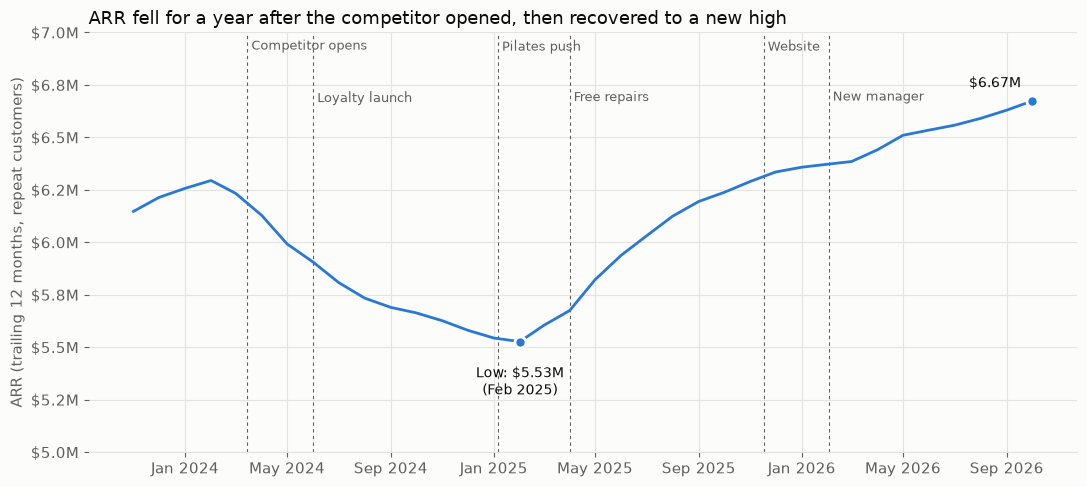

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arr.index, arr / 1e6, color=BLUE)
ax.plot([trough_m, arr.index[-1]], [arr.min() / 1e6, arr.iloc[-1] / 1e6], "o", color=BLUE, ms=8,
        mec="#fcfcfb", mew=2, zorder=3)
ax.annotate(f"Low: ${arr.min()/1e6:.2f}M\n({trough_m:%b %Y})", (trough_m, arr.min() / 1e6),
            xytext=(0, -38), textcoords="offset points", ha="center", color=INK, fontsize=10)
ax.annotate(f"${arr.iloc[-1]/1e6:.2f}M", (arr.index[-1], arr.iloc[-1] / 1e6),
            xytext=(-8, 10), textcoords="offset points", ha="right", color=INK, fontsize=10)
ax.set_ylim(5.0, 7.0)
mark_events(ax, 7.0)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:.1f}M"))
ax.set_title("ARR fell for a year after the competitor opened, then recovered to a new high",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("ARR (trailing 12 months, repeat customers)")
fig.tight_layout()
plt.show()

**What drove the recovery?** Each month's repeat revenue and active repeat customers, compared with the **same
calendar month in Mar 2023 – Feb 2024** (the year before the competitor), which removes seasonality.
Revenue is back above pre-competitor levels, but customers are not: the recovery is fewer customers spending more.

In [5]:
rv = visits[visits["is_repeat_visit"]]
g = rv.groupby("month").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
base = g.loc["2023-03-01":"2024-02-01"].copy()
base.index = base.index.month

rows = {}
for name, (a, b) in {"Year 1 (Mar 2024 – Feb 2025)": ("2024-03-01", "2025-02-01"),
                     "Year 2 (Mar 2025 – Feb 2026)": ("2025-03-01", "2026-02-01"),
                     "Year 3 so far (Mar – Oct 2026)": ("2026-03-01", "2026-10-01")}.items():
    p, bm = g.loc[a:b], base.loc[g.loc[a:b].index.month]
    rows[name] = {
        "repeat revenue vs pre-competitor (%)": (p.revenue.sum() / bm.revenue.sum() - 1) * 100,
        "active repeat customers vs pre-competitor (%)": (p.customers.mean() / bm.customers.mean() - 1) * 100,
        "revenue per active customer vs pre-competitor (%)":
            ((p.revenue.sum() / p.customers.sum()) / (bm.revenue.sum() / bm.customers.sum()) - 1) * 100,
    }
pd.DataFrame(rows).T.round(1)

,repeat revenue vs pre-competitor (%),active repeat customers vs pre-competitor (%),revenue per active customer vs pre-competitor (%)
Year 1 (Mar 2024 – Feb 2025),-12.2,-18.7,8.0
Year 2 (Mar 2025 – Feb 2026),1.2,-8.8,11.0
Year 3 so far (Mar – Oct 2026),10.4,-5.3,16.6


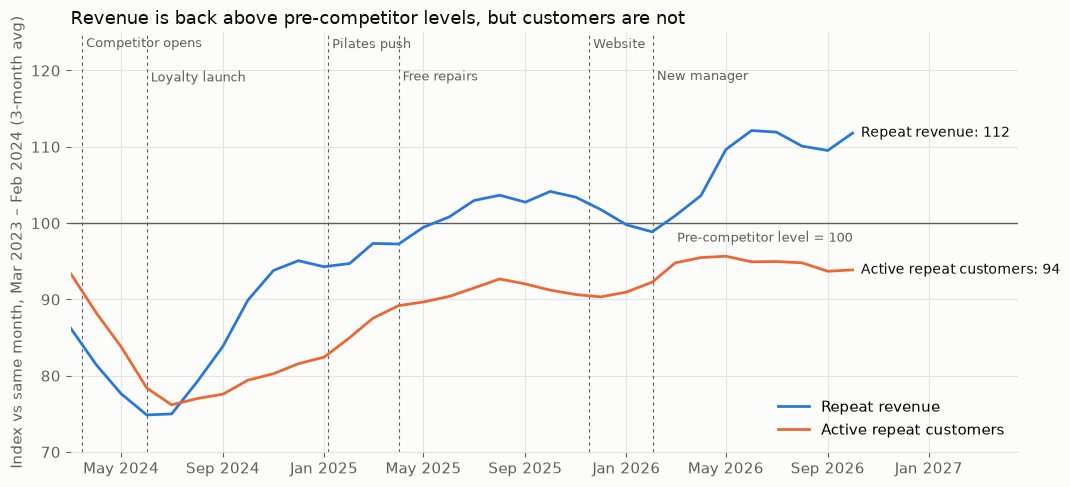

In [6]:
post = g.loc["2024-03-01":]
idx = (post.div(base.loc[post.index.month].values) * 100).rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.axhline(100, color=INK2, lw=1)
for col, colr, lab in [("revenue", BLUE, "Repeat revenue"), ("customers", ORANGE, "Active repeat customers")]:
    ax.plot(idx.index, idx[col], color=colr, label=lab)
    ax.annotate(f"{lab}: {idx[col].iloc[-1]:.0f}", (idx.index[-1], idx[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.text(pd.Timestamp("2026-10-01"), 99, "Pre-competitor level = 100", color=INK2, fontsize=9, va="top", ha="right")
ax.set_ylim(70, 125)
mark_events(ax, 125)
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.Timedelta(days=200))
ax.set_title("Revenue is back above pre-competitor levels, but customers are not", loc="left", color=INK, fontsize=13)
ax.set_ylabel("Index vs same month, Mar 2023 – Feb 2024 (3-month avg)")
fig.tight_layout()
plt.show()

## 4. Competitor impact & seasonality (Stream A, slide 5)
The competitor opened on **15 March 2024**, and sales to young shoppers dropped that same day: 18–24 year-olds spent
normally on 1–14 March (+2% vs the same days of 2023), then 50% less on 15–31 March.

**How we compare:** sales swing a lot with the seasons (December is about twice a normal month), so we always compare
the **same months in different years**, e.g. March–October 2024 vs March–October 2023. We use March–October because the
data ends in October 2026, so those months exist in every year. Every step is explained in the notebooks in
`analysis/a_competitor/`.

- **The competitor took young shoppers, and they never came back.** Sales to 18–24 year-olds fell about 45% and are
  still about 45% below 2023. Every older age group now buys *more* than in 2023, so the store's recovery comes
  entirely from shoppers aged 25 and over.
- **Fewer young people start shopping here, and fewer of them return.** Half as many 18–24 year-olds shop at Lululime
  for the first time, and young shoppers went from coming back as often as everyone else to coming back the least.
- **The seasons are large and must be accounted for:** December sells about twice a normal month, and jackets make
  half their yearly sales in November–January. Free repairs started in April, just as jacket sales naturally fall.

In [7]:
a_p = lines[lines["row_type"] == C.PURCHASE].copy()
a_p["year"], a_p["mon"] = a_p["date"].dt.year, a_p["date"].dt.month
A_AGES = ["18-24", "25-34", "35-44", "45-54", "55+"]


def a_mar_oct(df, year):
    """Mar–Oct of a year: the longest window that exists in all of 2023–2026 (data ends Oct 2026)."""
    return df[(df["year"] == year) & df["mon"].between(3, 10)]


a_rev = pd.DataFrame({y: a_mar_oct(a_p, y).groupby("age_band")["revenue"].sum() for y in [2023, 2024, 2025, 2026]})
a_cat = pd.DataFrame({y: a_mar_oct(a_p, y).groupby("category")["revenue"].sum() for y in [2023, 2024, 2025]})
a_lost = (a_rev[2024] - a_rev[2023]).loc[A_AGES]

a_new = customers[customers["signup_date"] >= C.DATA_START]
a_new = a_new[a_new["signup_date"].dt.month.between(3, 10)]
a_new = a_new.groupby([a_new["signup_date"].dt.year, "age_band"]).size().unstack()

pd.Series({
    "Sales to 18-24 year-olds, Mar–Oct 2024 vs 2023 (%)": (a_rev.loc["18-24", 2024] / a_rev.loc["18-24", 2023] - 1) * 100,
    "Sales to 18-24 year-olds, Mar–Oct 2026 vs 2023 (%)": (a_rev.loc["18-24", 2026] / a_rev.loc["18-24", 2023] - 1) * 100,
    "Sales to shoppers aged 25+, Mar–Oct 2026 vs 2023 (%)": (a_rev.loc[A_AGES[1:], 2026].sum() / a_rev.loc[A_AGES[1:], 2023].sum() - 1) * 100,
    "Share of the 2024 sales drop caused by 18-24 year-olds (%)": a_lost["18-24"] / a_lost.sum() * 100,
    "Share of 2023 sales from 18-24 year-olds (%)": a_rev.loc["18-24", 2023] / a_rev[2023].sum() * 100,
    "First-time 18-24 shoppers, Mar–Oct 2024 vs 2023 (%)": (a_new.loc[2024, "18-24"] / a_new.loc[2023, "18-24"] - 1) * 100,
    "Leggings sales, Mar–Oct 2024 vs 2023 (%)": (a_cat.loc["Leggings", 2024] / a_cat.loc["Leggings", 2023] - 1) * 100,
    "Jacket (outerwear) sales, Mar–Oct 2025 vs 2023 (%)": (a_cat.loc["Outerwear", 2025] / a_cat.loc["Outerwear", 2023] - 1) * 100,
}).round(1)

Sales to 18-24 year-olds, Mar–Oct 2024 vs 2023 (%)           -45.2
Sales to 18-24 year-olds, Mar–Oct 2026 vs 2023 (%)           -47.0
Sales to shoppers aged 25+, Mar–Oct 2026 vs 2023 (%)          22.5
Share of the 2024 sales drop caused by 18-24 year-olds (%)    53.2
Share of 2023 sales from 18-24 year-olds (%)                  19.3
First-time 18-24 shoppers, Mar–Oct 2024 vs 2023 (%)          -46.4
Leggings sales, Mar–Oct 2024 vs 2023 (%)                     -30.2
Jacket (outerwear) sales, Mar–Oct 2025 vs 2023 (%)            -9.6
dtype: float64

**Who was hit, and when.** Each line compares a month's sales with the same month one year earlier (0% = no change).
Young shoppers (orange) were growing until February 2024, then bought 40–55% less from March. Older shoppers (grey)
dipped briefly and were back to normal by late 2024. From March 2025 each month is compared with a weak month right after
the competitor opened, so the jumps there look better than reality.

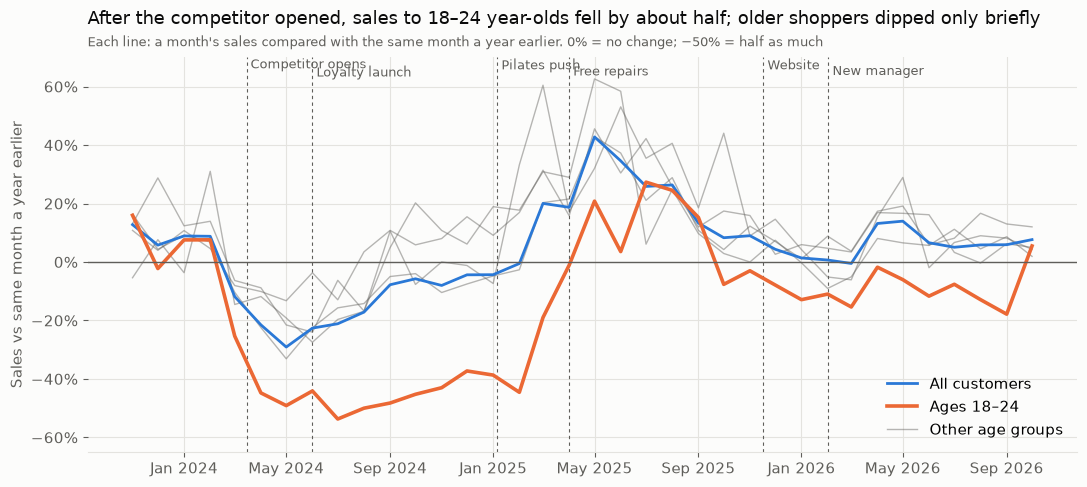

In [8]:
a_monthly = a_p.pivot_table(index="month", columns="age_band", values="revenue", aggfunc="sum")
a_monthly["All customers"] = a_monthly[A_AGES + ["Unknown"]].sum(axis=1)
a_yoy = a_monthly.pct_change(12, fill_method=None).loc["2023-11-01":] * 100

fig, ax = plt.subplots(figsize=(11, 5))
for a in A_AGES[1:]:
    ax.plot(a_yoy.index, a_yoy[a], color=INK2, lw=1, alpha=0.45)
ax.plot(a_yoy.index, a_yoy["All customers"], color=BLUE, label="All customers")
ax.plot(a_yoy.index, a_yoy["18-24"], color=ORANGE, lw=2.6, label="Ages 18–24")
ax.plot([], [], color=INK2, lw=1, alpha=0.45, label="Other age groups")
ax.axhline(0, color=INK2, lw=1)
ax.set_ylim(-65, 70)
mark_events(ax, 70)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right", frameon=False)
ax.set_title("After the competitor opened, sales to 18–24 year-olds fell by about half; older shoppers dipped only briefly",
             loc="left", color=INK, fontsize=13, pad=24)
ax.text(0, 1.02, "Each line: a month's sales compared with the same month a year earlier. 0% = no change; −50% = half as much",
        transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")
ax.set_ylabel("Sales vs same month a year earlier")
fig.tight_layout()
plt.show()

**Fewer young people come back, and fewer start shopping here.** Before the competitor opened, young shoppers were as
likely as anyone to come back the following winter. The winter it opened, the share who came back fell twice as much
for them as for older shoppers, and it has stayed behind since. Over the same period, half as many 18–24 year-olds
shopped here for the first time (table below). Together, the number of young shoppers fell from 1,513 (March–October
2023) to 725 (March–October 2026). We compare winters (November–February) because that's the only stretch the data
covers twice before the competitor opened.

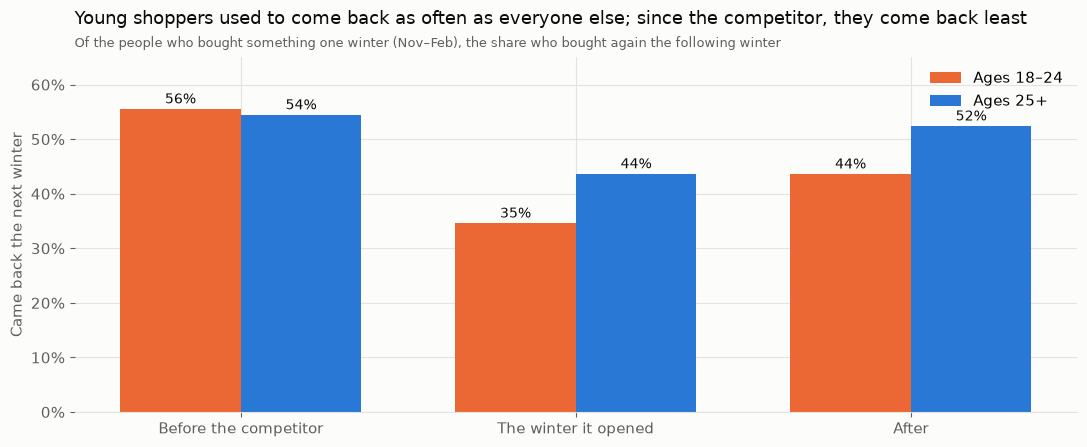

age_band,18-24,25-34,35-44,45-54,55+
"First-time shoppers, Mar–Oct of",,,,,
2023,420,555,337,211,87
2024,225,593,393,178,87
2025,244,619,375,189,114
2026,201,539,336,175,102


In [9]:
a_age = customers.set_index("customer_id")["age_band"]
A_WINTERS = [("2022-11-01", "2023-03-01"), ("2023-11-01", "2024-03-01"),
             ("2024-11-01", "2025-03-01"), ("2025-11-01", "2026-03-01")]


def a_active(start, end):
    return set(a_p.loc[(a_p["date"] >= start) & (a_p["date"] < end), "customer_id"])


a_ret = {}
for (s0, e0), (s1, e1), label in zip(A_WINTERS, A_WINTERS[1:],
                                     ["Before the competitor", "The winter it opened", "After"]):
    base_ids = pd.Series(sorted(a_active(s0, e0)))
    back = base_ids.isin(a_active(s1, e1))
    young = base_ids.map(a_age).eq("18-24").values
    a_ret[label] = {"Ages 18–24": back[young].mean() * 100,
                    "Ages 25+": back[base_ids.map(a_age).isin(A_AGES[1:]).values].mean() * 100}
a_ret = pd.DataFrame(a_ret).T

fig, ax = plt.subplots(figsize=(11, 4.6))
a_x = range(len(a_ret))
for i, (col, colr) in enumerate([("Ages 18–24", ORANGE), ("Ages 25+", BLUE)]):
    xs = [x + (i - 0.5) * 0.36 for x in a_x]
    ax.bar(xs, a_ret[col], 0.36, color=colr, label=col)
    for x, v in zip(xs, a_ret[col]):
        ax.text(x, v + 1, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(list(a_x), a_ret.index)
ax.set_ylim(0, 65)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="upper right", frameon=False)
ax.set_title("Young shoppers used to come back as often as everyone else; since the competitor, they come back least",
             loc="left", color=INK, fontsize=13, pad=24)
ax.text(0, 1.02, "Of the people who bought something one winter (Nov–Feb), the share who bought again the following winter",
        transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")
ax.set_ylabel("Came back the next winter")
fig.tight_layout()
plt.show()

a_new[A_AGES].rename_axis("First-time shoppers, Mar–Oct of").astype(int)

**The seasons.** Each number below compares a month's sales with an average month for that product: 100 = average,
200 = twice as much, 50 = half (averaged over the four years of data; four different calculation methods give nearly
the same result, see `analysis/a_competitor/a2_seasonality.ipynb`). December sells about twice a normal month.
Jackets and hoodies sell about 3× normal in December and very little in summer; shorts and tank tops are the opposite.
The two holiday sales (Black Friday weekend and Boxing Week) are only 9 days and about 5% of yearly sales, so most of
the holiday rush is full-price shopping.
**Why it matters for the programs:** loyalty started in June and free repairs in April, both quiet months. Comparing
"before vs after" either launch without accounting for the season would be misleading, especially for jackets.

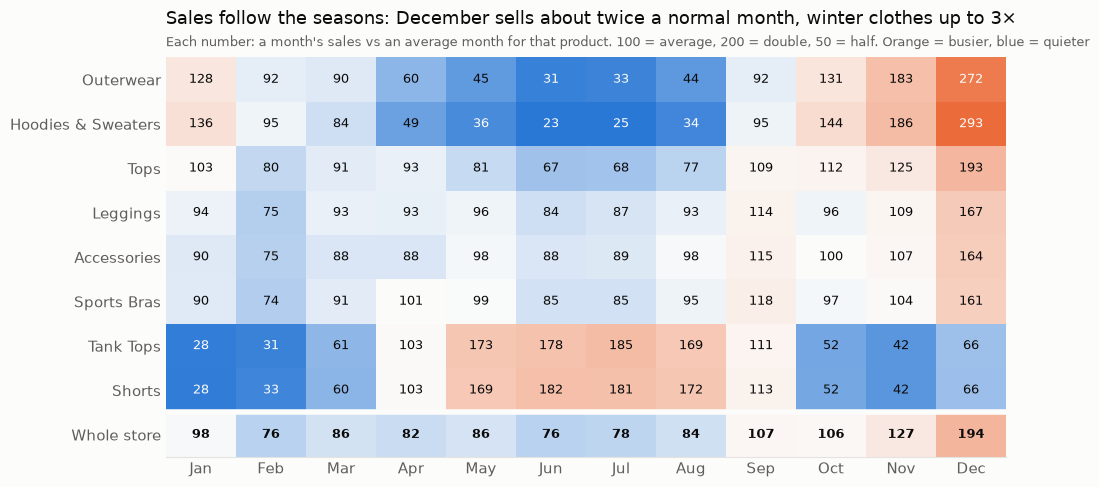

In [10]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

A_MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
a_cm = a_p.groupby(["category", "mon"])["revenue"].sum().unstack() / 4
a_heat = a_cm.div(a_cm.mean(axis=1), axis=0) * 100
a_heat = a_heat.loc[["Outerwear", "Hoodies & Sweaters", "Tops", "Leggings", "Accessories",
                     "Sports Bras", "Tank Tops", "Shorts"]]
a_store = a_p.groupby("mon")["revenue"].sum() / 4
a_heat.loc["Whole store"] = a_store / a_store.mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
a_cmap = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#fcfcfb", ORANGE])
ax.imshow(a_heat.values, cmap=a_cmap, norm=TwoSlopeNorm(vcenter=100, vmin=25, vmax=300), aspect="auto")
ax.set_xticks(range(12), A_MONTHS)
ax.set_yticks(range(len(a_heat)), a_heat.index)
ax.axhline(len(a_heat) - 1.5, color="#fcfcfb", lw=4)
ax.grid(False)
ax.tick_params(length=0)
for i in range(a_heat.shape[0]):
    for j in range(12):
        v = a_heat.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="#fcfcfb" if (v > 220 or v < 40) else INK,
                fontweight="bold" if a_heat.index[i] == "Whole store" else "normal")
ax.set_title("Sales follow the seasons: December sells about twice a normal month, winter clothes up to 3×",
             loc="left", color=INK, fontsize=13, pad=24)
ax.text(0, 1.02, "Each number: a month's sales vs an average month for that product. 100 = average, 200 = double, 50 = half. "
        "Orange = busier, blue = quieter", transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")
fig.tight_layout()
plt.show()

## 5. Loyalty program: revenue vs profit, points-funded returns (Stream B, slide 6)
Leadership credits loyalty for the recovery and wants to expand it. Full analysis: `analysis/b_loyalty/b_loyalty.py`.

- **Members grew spend more than similar non-members** (+$1,110 revenue, +$609 profit per member in the year after
  launch, within age band × pre-launch spend quartile, customers active in both years). About 55% of the extra revenue
  reaches profit, the same as the store's normal margin, so points don't eat the gain. **But this is an upper bound:**
  joiners were already the keenest shoppers, and the churn model (D-4) detects **no separate retention effect** of
  membership once engagement is controlled (odds ratio 0.99; a weak test, since 93% of revenue is from members).
- **The cost of points has levelled off at a structural level:** $797K since launch (5.0% of revenue), $413K in the last 12 months (5.9%),
  up from 2.4% of revenue in the first full quarter, flat at 5.5–6.5% since mid-2025. Balances aren't building up
  (only $127K outstanding); the rise came from tier mix (Gold went from 3% to 69% of member spend; computed in section 9). Each extra
  0.25 pts per $ would cost about $81K a year (decision #24).
- **Purchases paid mostly with points are returned 2.4× as often** (24% vs ~10%).
- **Being close to the next tier doesn't change spending** (baskets $156–$164 at every distance), so the tier
  mechanic isn't driving extra spend.

In [11]:
L = C.LOYALTY_LAUNCH
b_pre = visits[(visits["date"] >= L - pd.DateOffset(years=1)) & (visits["date"] < L)]
b_post = visits[(visits["date"] >= L) & (visits["date"] < L + pd.DateOffset(years=1))]
b_cols = ["revenue", "profit"]
b = (b_pre.groupby("customer_id")[b_cols].sum().add_suffix("_pre")
     .join(b_post.groupby("customer_id")[b_cols].sum().add_suffix("_post"), how="inner")   # active in both years
     .join(customers.set_index("customer_id")[["age_band", "loyalty_join_date"]]))
b["member"] = b["loyalty_join_date"].notna() & (b["loyalty_join_date"] < L + pd.DateOffset(years=1))
b["spend_q"] = pd.qcut(b["revenue_pre"], 4, labels=False)
b["d_rev"], b["d_prof"] = b["revenue_post"] - b["revenue_pre"], b["profit_post"] - b["profit_pre"]
b_cell = b.groupby(["age_band", "spend_q", "member"])[["d_rev", "d_prof"]].mean().unstack("member")
b_did = pd.DataFrame({k: b_cell[k][True] - b_cell[k][False] for k in ["d_rev", "d_prof"]}).dropna()
b_w = b[b["member"]].groupby(["age_band", "spend_q"]).size().reindex(b_did.index)
b_total = b_did.mul(b_w, axis=0).sum() / b_w.sum()
print(f"{len(b):,} customers active in both years, {b['member'].sum():,} joined in year 1. Matched extra per member: "
      f"revenue ${b_total['d_rev']:,.0f}, profit ${b_total['d_prof']:,.0f} "
      f"({b_total['d_prof'] / b_total['d_rev']:.0%} reaches profit)")
(b_did.mul(b_w, axis=0).groupby("age_band").sum().div(b_w.groupby("age_band").sum(), axis=0)
 .rename(columns={"d_rev": "extra revenue / member ($)", "d_prof": "extra profit / member ($)"}).round(0))

3,798 customers active in both years, 2,565 joined in year 1. Matched extra per member: revenue $1,110, profit $609 (55% reaches profit)


,extra revenue / member ($),extra profit / member ($)
age_band,,
18-24,683.0,380.0
25-34,1214.0,683.0
35-44,1133.0,600.0
45-54,1437.0,782.0
55+,1211.0,641.0
Unknown,547.0,311.0


In [12]:
b_since = visits[visits["date"] >= L]
b_q = b_since.groupby(b_since["date"].dt.to_period("Q"))[["redeemed_dollars", "revenue"]].sum()
print(f"Redeemed points since launch: ${b_since['redeemed_dollars'].sum():,.0f} "
      f"({b_since['redeemed_dollars'].sum() / b_since['revenue'].sum():.1%} of revenue)")
(b_q["redeemed_dollars"] / b_q["revenue"] * 100).round(1).rename("redeemed, % of revenue")

Redeemed points since launch: $796,635 (5.0% of revenue)


date
2024Q2    0.6
2024Q3    2.4
2024Q4    3.9
2025Q1    5.0
2025Q2    5.8
2025Q3    5.4
2025Q4    5.3
2026Q1    6.2
2026Q2    6.5
2026Q3    5.7
2026Q4    5.5
Freq: Q-DEC, Name: redeemed, % of revenue, dtype: float64

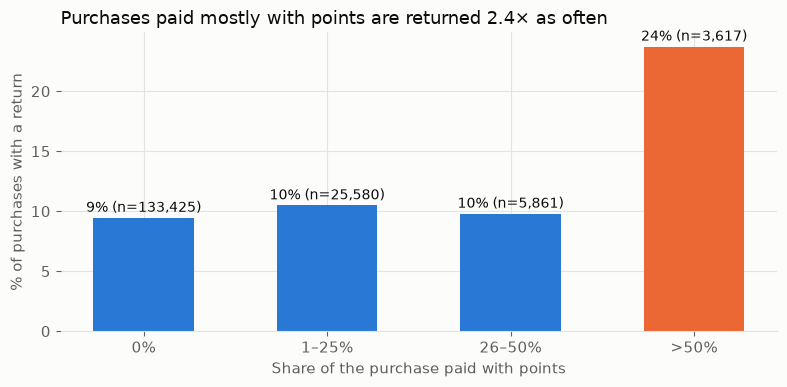

In [13]:
b_buy = lines[lines["row_type"] == C.PURCHASE].groupby("transaction_id")["revenue"].sum().to_frame()
b_buy = b_buy.join(visits.set_index("transaction_id")["redeemed_dollars"])
b_buy = b_buy[b_buy["revenue"] > 0]
b_buy["bucket"] = pd.cut((b_buy["redeemed_dollars"] / b_buy["revenue"]).clip(upper=1),
                         [-0.001, 0, 0.25, 0.5, 1.0], labels=["0%", "1–25%", "26–50%", ">50%"])
b_buy["returned"] = b_buy.index.isin(set(lines.loc[lines["row_type"] == "Return", "original_transaction_id"].dropna()))
b_ret = b_buy.groupby("bucket", observed=True)["returned"].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(b_ret.index.astype(str), b_ret["mean"] * 100, 0.55, color=[BLUE] * 3 + [ORANGE])
for x, (n, r) in enumerate(b_ret.values):
    ax.text(x, r * 100 + 0.5, f"{r:.0%} (n={n:,.0f})", ha="center", color=INK, fontsize=10)
ax.set_xlabel("Share of the purchase paid with points")
ax.set_ylabel("% of purchases with a return")
ax.set_title("Purchases paid mostly with points are returned 2.4× as often", loc="left", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

## 6. Repairs: churn and cost vs ARR at risk, with scenarios (Stream C, slides 7-8)
Leadership says repairs "only cost money". We test that by asking whether repair users stay longer, and whether
what they bring in outweighs what repairs cost. Full analysis: `analysis/c_repairs/` (C-1, C-2).

- **Repair users stop shopping less often than similar customers: about 16 points.** A simple matched comparison
  (age × spend) shows a much bigger gap, but it is biased by timing: users who started repairing late cannot yet count
  as churned, and many non-users had already left before repairs existed. The fair-timing **landmark** comparison
  (customers buying Apr–Sep 2025; users = repaired by Sep 2025; matched on age, pre-launch spend and Apr–Sep 2025
  visits) gives about **16 points** (decision #25). We use that, not the biased gap.
- **After controlling for engagement, the model-adjusted association is 5–9 points.** A churn prediction model
  (logistic regression and boosted trees, computed below) switches repair use off for each repair user, holding
  visits, spend, recency, tier and demographics fixed. This is observational evidence, not a proven causal effect.
- **Slow repairs go with churn:** 24% churn when a user's typical turnaround is over 20 days, vs 11–13% otherwise.
- **Closing repairs is about break-even on profit.** It saves $134K a year of repair cost but puts profit at risk.
  Scoring each current repair user's own ARR, the two models' central estimates of the net effect are **−$67K and
  +$55K a year**; their 90% bootstrap ranges together span about **−$123K to +$83K**. The stakes are under 1% of
  revenue, with more room to lose than to gain: scrapping repairs is not the saving leadership expects.
- **No sign of outerwear cannibalization.** Outerwear did fall 12% after launch, but repair users' outerwear spend
  *rose* 10%. The whole drop came from customers who never used repairs.

**Who we compare.** Only customers who visited in the year before repairs launched (Apr 2024 – Mar 2025), so everyone
could have used repairs. Users are compared with non-users in the same age band × pre-launch spend quartile, weighted
by the number of users per cell. Raw churn (13% vs 77%) mostly compares engaged with lapsed customers: 56% of non-users
in this cohort stopped visiting *before* repairs existed. Requiring a purchase after launch helps, but the gap is still
inflated by timing, so the table below is the **biased first pass**; the landmark comparison that follows is the one
we use. Counting purchase visits only (a pickup trip is a visit) changes the gap by less than 1 point.

In [14]:
c_pre = visits[visits["date"].between(C.REPAIRS_LAUNCH - pd.DateOffset(years=1),
                                      C.REPAIRS_LAUNCH - pd.Timedelta(days=1))]
c_cust = customers.set_index("customer_id")
c_coh = c_cust.loc[c_pre["customer_id"].unique()].copy()
c_coh["pre_spend"] = c_pre.groupby("customer_id")["revenue"].sum()
c_coh["spend_q"] = pd.qcut(c_coh["pre_spend"].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
c_last_buy = visits[visits["has_purchase"]].groupby("customer_id")["date"].max()
c_coh["churned_purchase"] = (C.AS_OF_DATE - c_coh.index.map(c_last_buy)).days > C.CHURN_DAYS
c_post = visits[(visits["date"] >= C.REPAIRS_LAUNCH) & visits["has_purchase"]]
c_coh["post_purchases"] = c_post.groupby("customer_id").size().reindex(c_coh.index).fillna(0)


def c_matched(d, col="churned", keys=("age_band", "spend_q"), user="used_repair"):
    """Churn of users vs non-users within matching cells (default age band × spend quartile), weighted by users per cell."""
    g = (d.groupby([*keys, user], observed=True)[col]
          .agg(["mean", "size"]).unstack(user).dropna())
    w = g[("size", True)]
    return {"Repair users": (g[("mean", True)] * w).sum() / w.sum(),
            "Non-users": (g[("mean", False)] * w).sum() / w.sum()}


c_still = c_coh[c_coh["post_purchases"] >= 1]
c_churn = pd.DataFrame({
    "Raw": c_coh.groupby("used_repair")["churned"].mean().rename({True: "Repair users", False: "Non-users"}),
    "Matched": c_matched(c_coh),
    "Matched, purchase visits only": c_matched(c_coh, "churned_purchase"),
    "Matched, still buying after launch": c_matched(c_still),
}).T[["Repair users", "Non-users"]]
c_churn["Gap (pts)"] = c_churn["Repair users"] - c_churn["Non-users"]
c_late = c_coh.loc[c_coh["used_repair"], "first_repair_date"] > C.AS_OF_DATE - pd.Timedelta(days=C.CHURN_DAYS)
print(f"Timing bias: {c_late.mean():.0%} of cohort repair users first repaired after "
      f"{C.AS_OF_DATE - pd.Timedelta(days=C.CHURN_DAYS):%d %b %Y}, so they cannot count as churned yet.")
(c_churn * 100).round(1)

Timing bias: 11% of cohort repair users first repaired after 04 May 2026, so they cannot count as churned yet.


,Repair users,Non-users,Gap (pts)
Raw,14.7,84.2,-69.4
Matched,14.7,81.1,-66.4
"Matched, purchase visits only",15.2,81.2,-66.0
"Matched, still buying after launch",14.8,65.7,-50.9


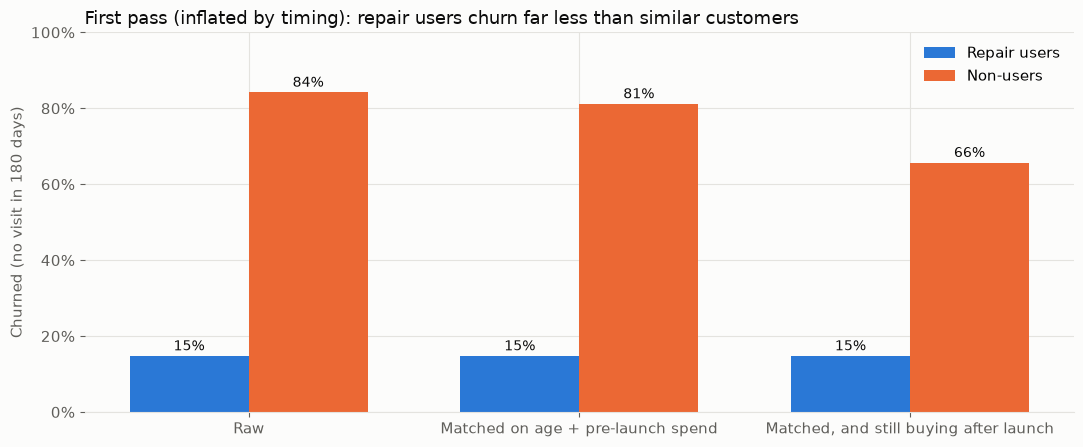

In [15]:
c_show = ["Raw", "Matched", "Matched, still buying after launch"]
c_x = range(len(c_show))
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (col, colr) in enumerate([("Repair users", BLUE), ("Non-users", ORANGE)]):
    xs = [x + (i - 0.5) * 0.36 for x in c_x]
    ax.bar(xs, c_churn.loc[c_show, col] * 100, 0.36, color=colr, label=col)
    for x, v in zip(xs, c_churn.loc[c_show, col] * 100):
        ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(list(c_x), ["Raw", "Matched on age + pre-launch spend", "Matched, and still buying after launch"])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="upper right", frameon=False)
ax.set_title("First pass (inflated by timing): repair users churn far less than similar customers",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("Churned (no visit in 180 days)")
fig.tight_layout()
plt.show()

**Landmark comparison (the gap we use).** Fix a landmark date, **30 Sep 2025**, so everyone has had the same chance
to use repairs and the same time to churn afterwards. Sample: cohort customers who made a purchase between the
repairs launch and the landmark. Users = first repair by the landmark. Churn = no purchase in the 180 days before the
end of the data. Matched within age band × pre-launch spend quartile × quartile of Apr–Sep 2025 purchase visits,
weighted by users per cell (decision #25, `docs/review/review_checks.py` section 5).

In [16]:
C_LANDMARK = pd.Timestamp("2025-09-30")
c_win = visits[(visits["date"] >= C.REPAIRS_LAUNCH) & (visits["date"] <= C_LANDMARK) & visits["has_purchase"]]
c_lm = c_coh.loc[c_coh.index.intersection(c_win["customer_id"].unique())].copy()
c_lm["early_user"] = c_lm["first_repair_date"] <= C_LANDMARK
c_lm["spend_q"] = pd.qcut(c_lm["pre_spend"].rank(method="first"), 4, labels=False)
c_lm["visit_q"] = pd.qcut(c_win.groupby("customer_id").size().reindex(c_lm.index).rank(method="first"), 4, labels=False)

c_land = pd.DataFrame({
    "Raw": c_lm.groupby("early_user")["churned_purchase"].mean().rename({True: "Repair users", False: "Non-users"}),
    "Matched: age × spend": c_matched(c_lm, "churned_purchase", user="early_user"),
    "Matched: age × spend × visits": c_matched(c_lm, "churned_purchase", ("age_band", "spend_q", "visit_q"), "early_user"),
}).T[["Repair users", "Non-users"]]
c_land["Gap (pts)"] = c_land["Repair users"] - c_land["Non-users"]
C_GAP = -c_land.loc["Matched: age × spend × visits", "Gap (pts)"]   # the landmark gap, used in the what-ifs below
print(f"Landmark sample: {len(c_lm):,} customers, {c_lm['early_user'].sum():,} repaired by {C_LANDMARK:%d %b %Y}. "
      f"Matched gap: {C_GAP * 100:.1f} pts")
(c_land * 100).round(1)

Landmark sample: 3,478 customers, 833 repaired by 30 Sep 2025. Matched gap: 15.8 pts


,Repair users,Non-users,Gap (pts)
Raw,17.0,50.8,-33.8
Matched: age × spend,17.0,42.5,-25.4
Matched: age × spend × visits,16.9,32.7,-15.8


**Turnaround.** Each repair user's median days from drop-off to pickup (median 13 days overall, range 5–47).
Not matched, and users in the slowest bucket also made fewer drop-offs, so read this as a warning sign, not proof.

In [17]:
c_rep = load("links").query("link_type == 'repair' and resolved")
c_days = c_rep.groupby("customer_id")["days_between"].median()
c_turn = (c_cust.loc[c_days.index]
          .assign(turnaround=pd.cut(c_days, [-float("inf"), 10, 20, float("inf")],
                                    labels=["≤10 days", "11–20 days", ">20 days"]))
          .groupby("turnaround", observed=True)
          .agg(churn_pct=("churned", "mean"), users=("churned", "size"), avg_dropoffs=("n_repair_dropoffs", "mean")))
c_turn["churn_pct"] *= 100
c_turn.round(1)

,churn_pct,users,avg_dropoffs
turnaround,,,
≤10 days,13.5,630,2.1
11–20 days,11.2,1209,2.9
>20 days,23.6,280,1.8


**Churn prediction model: how much of the gap is left once engagement is controlled?** (D-4, full notebook:
`analysis/d_customers_arr/d3_churn_model.ipynb`.) Snapshot at **T = 30 Apr 2026**: every feature uses data up to T
only, and the label is **no visit in the next 180 days**. Population: customers with a visit in the 12 months
before T. Features: visits, purchase visits, spend, points redeemed and returns in the last 12 months, days since
last purchase, tenure, membership, Silver/Gold tier, repair use, interests, age band, channel, home area.
Two models: logistic regression and gradient-boosted trees (trained on 75%, AUC on the other 25%).

**Model-adjusted association:** for each repair user, predict churn as they are and again with repair use switched
off, everything else unchanged. The average difference is the repair association after controls. It is
observational: the model holds fixed what we can measure, not unmeasured engagement, so it is not a proven effect.

In [18]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

M_T, M_HORIZON, M_SEED = pd.Timestamp("2026-04-30"), 180, 42
M_NUM = ["visits_12m", "purchase_visits_12m", "revenue_12m", "redeemed_12m", "returns_12m",
         "days_since_last_purchase", "tenure_years"]
M_BIN = ["used_repair", "member", "silver_or_gold",
         "interest_run", "interest_yoga", "interest_pilates", "interest_outdoor", "interest_lifestyle"]
M_CAT = ["age_band", "acquisition_channel", "home_area"]


def m_features(at):
    """One row per customer with a visit in the 12 months up to `at`; every feature uses data up to `at` only."""
    past = visits[visits["date"] <= at]
    l12 = past[past["date"] > at - pd.Timedelta(days=365)]
    f = customers.set_index("customer_id").loc[l12["customer_id"].unique()].copy()
    g = l12.groupby("customer_id")
    f["visits_12m"] = g.size()
    f["purchase_visits_12m"] = g["has_purchase"].sum()
    f["revenue_12m"] = g["revenue"].sum()
    f["redeemed_12m"] = g["redeemed_dollars"].sum()
    f["returns_12m"] = g["has_return"].sum()
    f["days_since_last_purchase"] = (at - past[past["has_purchase"]].groupby("customer_id")["date"].max()).dt.days
    f["days_since_last_purchase"] = f["days_since_last_purchase"].fillna(730)
    f["tenure_years"] = (at - f["signup_date"]).dt.days / 365
    f["member"] = (f["loyalty_join_date"] <= at).fillna(False).astype(int)
    last_tier = past.sort_values("datetime").groupby("customer_id")["tier"].last()
    f["silver_or_gold"] = last_tier.reindex(f.index).isin(["Silver", "Gold"]).astype(int)
    drops = past[past["has_dropoff"]].groupby("customer_id").size()
    f["used_repair"] = (drops.reindex(f.index).fillna(0) > 0).astype(int)
    return f


m_pop = m_features(M_T)
m_future = visits[(visits["date"] > M_T) & (visits["date"] <= M_T + pd.Timedelta(days=M_HORIZON))]
m_pop["churn"] = (~m_pop.index.isin(m_future["customer_id"])).astype(int)
m_X, m_y = m_pop[M_NUM + M_BIN + M_CAT], m_pop["churn"]


def m_model(kind):
    if kind == "Logistic regression":
        prep = ColumnTransformer([("num", StandardScaler(), M_NUM), ("bin", "passthrough", M_BIN),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), M_CAT)])
        return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])
    prep = ColumnTransformer([("num", "passthrough", M_NUM + M_BIN),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), M_CAT)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, random_state=M_SEED))])


M_KINDS = ["Logistic regression", "Gradient-boosted trees"]
X_tr, X_te, y_tr, y_te = train_test_split(m_X, m_y, test_size=0.25, stratify=m_y, random_state=M_SEED)
m_effect = {}
for kind in M_KINDS:
    auc = roc_auc_score(y_te, m_model(kind).fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
    full = m_model(kind).fit(m_X, m_y)
    users = m_X[m_X["used_repair"] == 1]
    lift = full.predict_proba(users.assign(used_repair=0))[:, 1] - full.predict_proba(users)[:, 1]
    m_effect[kind] = {"test AUC": auc, "model-adjusted association (pts)": lift.mean() * 100}
m_effect = pd.DataFrame(m_effect).T
print(f"{len(m_pop):,} customers at T · churn {m_y.mean():.1%} · repair users {m_pop['used_repair'].mean():.1%} · "
      f"raw gap {(m_pop.groupby('used_repair')['churn'].mean().diff().iloc[-1]) * -100:.1f} pts")
m_effect.round(3)

6,129 customers at T · churn 42.1% · repair users 29.2% · raw gap 37.2 pts


,test AUC,model-adjusted association (pts)
Logistic regression,0.843,8.616
Gradient-boosted trees,0.836,5.124


**Forecast: profit at risk if repairs closed today.** Score every **current** repair user (features at 31 Oct 2026)
with the T-snapshot models, as they are and with repair use switched off. ARR at risk = Σ (rise in churn
probability × that customer's current ARR); next year's new repair users are added at last year's rate (half a
year on average). Profit at risk = ARR at risk × the store's margin before repair cost (last 12 months). The range
comes from refitting both models on 40 bootstrap resamples each. Takes about two minutes.

In [19]:
m_cur = m_features(C.DATA_END)
m_users_now = m_cur[m_cur["used_repair"] == 1]
m_Xu = m_users_now[M_NUM + M_BIN + M_CAT]
m_last_year = visits[visits["date"] > C.DATA_END - pd.Timedelta(days=365)]
m_margin = (m_last_year["profit"].sum() + m_last_year["repair_cost"].sum()) / m_last_year["revenue"].sum()
c_cost = m_last_year["repair_cost"].sum()        # repair cost saved by closing, last 12 months
m_new_users = int((customers["first_repair_date"] > C.DATA_END - pd.Timedelta(days=365)).sum())

rng = np.random.default_rng(M_SEED)
m_boot = []
for kind in M_KINDS:
    for _ in range(40):
        idx = rng.integers(0, len(m_X), len(m_X))
        mdl = m_model(kind).fit(m_X.iloc[idx], m_y.iloc[idx])
        lift = mdl.predict_proba(m_Xu.assign(used_repair=0))[:, 1] - mdl.predict_proba(m_Xu)[:, 1]
        arr_now = float((lift * m_users_now["arr_12m"]).sum())
        arr_all = arr_now + arr_now / len(m_users_now) * m_new_users * 0.5
        m_boot.append({"model": kind, "profit_at_risk": arr_all * m_margin})
m_boot = pd.DataFrame(m_boot)
m_boot["net_of_closing"] = c_cost - m_boot["profit_at_risk"]

c_forecast = m_boot.groupby("model").agg(
    profit_at_risk_central=("profit_at_risk", "median"),
    net_central=("net_of_closing", "median"),
    net_low_5pct=("net_of_closing", lambda s: s.quantile(0.05)),
    net_high_95pct=("net_of_closing", lambda s: s.quantile(0.95)),
    runs_where_closing_loses_money_pct=("net_of_closing", lambda s: (s < 0).mean() * 100),
).reindex(M_KINDS)
C_NET_LOW, C_NET_HIGH = c_forecast["net_low_5pct"].min(), c_forecast["net_high_95pct"].max()
print(f"Repair cost saved by closing: ${c_cost:,.0f} · {len(m_users_now):,} current repair users · "
      f"{m_new_users:,} new users a year · margin before repair cost {m_margin:.1%}")
print(f"Net effect of closing, central estimates: " + " and ".join(
    f"{k}: ${v / 1e3:+,.0f}K" for k, v in c_forecast["net_central"].items()))
print(f"90% bootstrap range across both models: ${C_NET_LOW / 1e3:+,.0f}K to ${C_NET_HIGH / 1e3:+,.0f}K a year")
c_show = c_forecast.copy()
c_show.iloc[:, :4] /= 1e3
c_show.columns = ["profit at risk, central ($K)", "net of closing, central ($K)", "net, 5th pct ($K)",
                  "net, 95th pct ($K)", "bootstrap runs where closing loses money (%)"]
c_show.round(0)

Repair cost saved by closing: $133,542 · 2,103 current repair users · 1,118 new users a year · margin before repair cost 57.2%
Net effect of closing, central estimates: Logistic regression: $-67K and Gradient-boosted trees: $+55K
90% bootstrap range across both models: $-123K to $+83K a year


,"profit at risk, central ($K)","net of closing, central ($K)","net, 5th pct ($K)","net, 95th pct ($K)",bootstrap runs where closing loses money (%)
model,,,,,
Logistic regression,201.0,-67.0,-123.0,-26.0,100.0
Gradient-boosted trees,78.0,55.0,26.0,83.0,0.0


**What-ifs (cross-check).** The same sum with a single average effect: repair users' ARR × effect × their margin
before repair cost. The break-even effect is the one at which profit lost equals the repair cost saved. The model's
5–9 pts sit just above break-even; the what-ifs show how much depends on what share of the 16-point landmark gap
repairs actually cause.

In [20]:
c_users = c_cust[c_cust["used_repair"]]
c_since = C.AS_OF_DATE - pd.DateOffset(months=C.ARR_WINDOW_MONTHS)
c_uv = visits[(visits["date"] > c_since) & visits["customer_id"].isin(c_users.index)]
c_margin = (c_uv["profit"] + c_uv["repair_cost"]).sum() / c_uv["revenue"].sum()
c_users_arr = c_users["arr_12m"].sum()
C_BREAK_EVEN_PTS = c_cost / (c_users_arr * c_margin)


def c_scenario(effect):
    """Yearly $K if repair users lose `effect` (share of customers) of retention when repairs are scrapped."""
    return {"ARR lost ($K)": c_users_arr * effect / 1e3,
            "Profit lost ($K)": c_users_arr * effect * c_margin / 1e3,
            "Repair cost saved ($K)": c_cost / 1e3,
            "Net from scrapping ($K)": (c_cost - c_users_arr * effect * c_margin) / 1e3}


c_scen = pd.DataFrame({**{f"Model-adjusted association ({k}, {v:.1f} pts)": c_scenario(v / 100)
                          for k, v in m_effect["model-adjusted association (pts)"].items()},
                       **{f"What-if: {s:.0%} of the landmark gap caused by repairs": c_scenario(C_GAP * s)
                          for s in [0.25, 0.5, 1.0]}}).T
print(f"Repair users' ARR: ${c_users_arr/1e6:.2f}M ({c_users_arr / c_cust['arr_12m'].sum():.0%} of company ARR) · "
      f"margin before repair cost {c_margin:.0%} · break-even effect {C_BREAK_EVEN_PTS:.1%} pts "
      f"({C_BREAK_EVEN_PTS / C_GAP:.0%} of the {C_GAP:.1%}-pt landmark gap)")
c_scen.round(0)

Repair users' ARR: $5.12M (77% of company ARR) · margin before repair cost 56% · break-even effect 4.6% pts (29% of the 15.8%-pt landmark gap)


,ARR lost ($K),Profit lost ($K),Repair cost saved ($K),Net from scrapping ($K)
"Model-adjusted association (Logistic regression, 8.6 pts)",441.0,248.0,134.0,-114.0
"Model-adjusted association (Gradient-boosted trees, 5.1 pts)",263.0,147.0,134.0,-14.0
What-if: 25% of the landmark gap caused by repairs,203.0,114.0,134.0,20.0
What-if: 50% of the landmark gap caused by repairs,406.0,228.0,134.0,-94.0
What-if: 100% of the landmark gap caused by repairs,812.0,456.0,134.0,-323.0


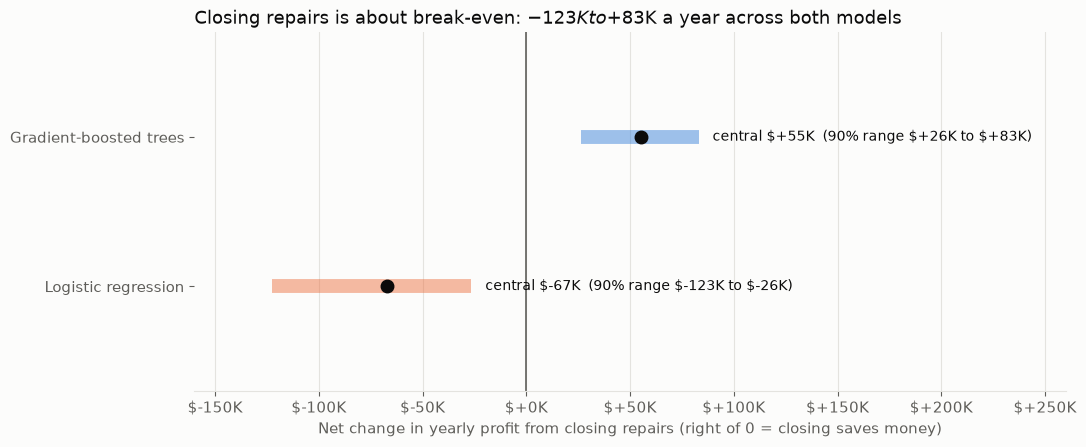

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.6))
c_rows = [(k, c_forecast.loc[k]) for k in M_KINDS]
for y, (k, r) in enumerate(c_rows):
    ax.plot([r["net_low_5pct"] / 1e3, r["net_high_95pct"] / 1e3], [y, y], color=ORANGE if r["net_central"] < 0 else BLUE,
            lw=10, solid_capstyle="butt", alpha=0.45)
    ax.plot(r["net_central"] / 1e3, y, "o", color=INK, ms=9)
    ax.annotate(f"central ${r['net_central'] / 1e3:+,.0f}K  (90% range ${r['net_low_5pct'] / 1e3:+,.0f}K to "
                f"${r['net_high_95pct'] / 1e3:+,.0f}K)", (r["net_high_95pct"] / 1e3, y), xytext=(10, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.axvline(0, color=INK2, lw=1.2)
ax.set_yticks(range(len(c_rows)), [k for k, _ in c_rows])
ax.set_ylim(-0.7, 1.7)
ax.set_xlim(-160, 260)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:+,.0f}K"))
ax.set_xlabel("Net change in yearly profit from closing repairs (right of 0 = closing saves money)")
ax.set_title(f"Closing repairs is about break-even: ${C_NET_LOW / 1e3:+,.0f}K to ${C_NET_HIGH / 1e3:+,.0f}K a year "
             "across both models", loc="left", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

**Do repairs cannibalize outerwear?** Leadership's second reason: a repaired jacket is a new jacket not bought.
(1) Store level: net outerwear revenue in the 12 months before vs after launch, split by whether the customer ever
used repairs. (2) Customer level: outerwear spend in the 12 months before vs after each customer's first repair,
for customers who repaired outerwear vs those who repaired **only activewear**. The second group is similar people
whose repairs can't replace a jacket. Only first repairs by Oct 2025, so everyone has 12 months after.
Full analysis: `analysis/c_repairs/c3_cannibalization.ipynb`.

In [22]:
c_sales = lines[lines["row_type"].isin([C.PURCHASE, C.RETURN])].copy()
c_sales["m"] = c_sales["date"].dt.to_period("M")
c_before = c_sales["date"].between(C.REPAIRS_LAUNCH - pd.DateOffset(years=1), C.REPAIRS_LAUNCH - pd.Timedelta(days=1))
c_after = c_sales["date"].between(C.REPAIRS_LAUNCH, C.REPAIRS_LAUNCH + pd.DateOffset(years=1) - pd.Timedelta(days=1))
c_ow = c_sales[c_sales["category"] == "Outerwear"]
c_grp = c_ow["customer_id"].map(c_cust["used_repair"]).map({True: "Repair users", False: "Never used repairs"})
c_ow_split = pd.DataFrame({"Before ($K)": c_ow[c_before[c_ow.index]].groupby(c_grp)["revenue"].sum() / 1e3,
                           "After ($K)": c_ow[c_after[c_ow.index]].groupby(c_grp)["revenue"].sum() / 1e3})
c_ow_split.loc["All customers"] = c_ow_split.sum()
c_ow_split["Change (%)"] = (c_ow_split["After ($K)"] / c_ow_split["Before ($K)"] - 1) * 100
c_ow_split.round(0)

,Before ($K),After ($K),Change (%)
customer_id,,,
Never used repairs,512.0,268.0,-48.0
Repair users,806.0,890.0,10.0
All customers,1318.0,1158.0,-12.0


In [23]:
c_drop = lines[lines["row_type"] == C.DROPOFF]
c_kind = {v: k for k, v in C.REPAIR_ITEMS.items()}
c_first_ow = c_drop[c_drop["item_id"] == c_kind["outerwear"]].groupby("customer_id")["date"].min().dt.to_period("M")
c_first_aw = c_drop[c_drop["item_id"] == c_kind["activewear"]].groupby("customer_id")["date"].min().dt.to_period("M")
c_first_aw = c_first_aw[~c_first_aw.index.isin(c_first_ow.index)]
c_months = pd.period_range(C.DATA_START, C.AS_OF_DATE, freq="M")
c_ow_m = c_ow.groupby(["customer_id", "m"])["revenue"].sum()
c_all_m = c_sales.groupby(["customer_id", "m"])["revenue"].sum()


def c_before_after(first):
    """Mean outerwear and other spend per customer, 12 months before vs from the month of first repair."""
    first = first[first <= (C.AS_OF_DATE - pd.DateOffset(months=12)).to_period("M")]
    ids = list(first.index)
    o = c_ow_m[c_ow_m.index.isin(ids, level=0)].unstack().reindex(index=ids, columns=c_months).fillna(0)
    a = c_all_m[c_all_m.index.isin(ids, level=0)].unstack().reindex(index=ids, columns=c_months).fillna(0)
    pre = [pd.period_range(m - 12, m - 1, freq="M") for m in first]
    post = [pd.period_range(m, m + 11, freq="M") for m in first]
    ob = sum(o.loc[c, p].sum() for c, p in zip(ids, pre)) / len(ids)
    oa = sum(o.loc[c, p].sum() for c, p in zip(ids, post)) / len(ids)
    ab = sum(a.loc[c, p].sum() for c, p in zip(ids, pre)) / len(ids)
    aa = sum(a.loc[c, p].sum() for c, p in zip(ids, post)) / len(ids)
    return {"Customers": len(ids), "Outerwear change (%)": (oa / ob - 1) * 100,
            "Everything else change (%)": ((aa - oa) / (ab - ob) - 1) * 100}


c_cannib = pd.DataFrame({"Repaired outerwear": c_before_after(c_first_ow),
                         "Repaired activewear only": c_before_after(c_first_aw)}).T
c_cannib.round(1)

,Customers,Outerwear change (%),Everything else change (%)
Repaired outerwear,705.0,-7.7,36.2
Repaired activewear only,189.0,-18.7,22.2


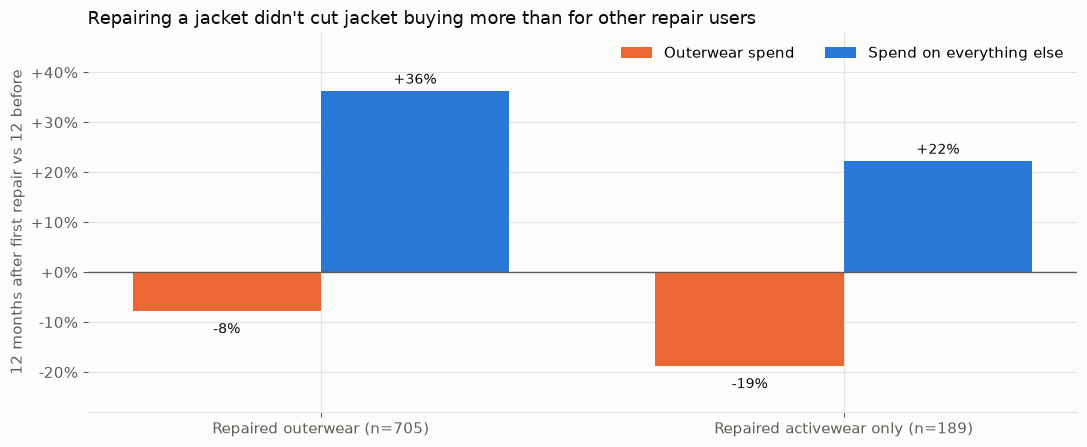

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (col, colr, lab) in enumerate([("Outerwear change (%)", ORANGE, "Outerwear spend"),
                                       ("Everything else change (%)", BLUE, "Spend on everything else")]):
    xs = [x + (i - 0.5) * 0.36 for x in range(len(c_cannib))]
    ax.bar(xs, c_cannib[col], 0.36, color=colr, label=lab)
    for x, v in zip(xs, c_cannib[col]):
        ax.text(x, v + (1.5 if v >= 0 else -4.5), f"{v:+.0f}%", ha="center", color=INK, fontsize=10)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(c_cannib)), [f"{g} (n={n:,.0f})" for g, n in c_cannib["Customers"].items()])
ax.set_ylim(-28, 48)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:+.0f}%"))
ax.legend(loc="upper right", frameon=False, ncol=2)
ax.set_title("Repairing a jacket didn't cut jacket buying more than for other repair users",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("12 months after first repair vs 12 before")
fig.tight_layout()
plt.show()

## 7. Does spending stay higher after joining loyalty or a first repair? (event study, Stream D)
Full notebook: `analysis/d_customers_arr/d6_attribution.ipynb`. **Linear regression on customer-months**
(Pilates recruits excluded): each customer's monthly repeat spend is explained by dummies for the months before and
after joining loyalty and before and after the first repair, plus a dummy for **every calendar month** (absorbs the
competitor, seasons, holiday sales, website and new manager) and **every customer** (each customer is compared with
themselves). Standard errors clustered by customer. The "before" windows show whether spending was already moving.

**Website check:** if the website (Nov 2025, shows tier and points) changed anything, it should lift long-standing
members more than non-members. We add "member since before Nov 2024 × after Nov 2025", with the same term a year
earlier as a placebo (no event in Nov 2024).

In [25]:
def ols_cluster(y, X, groups):
    """OLS with cluster-robust standard errors (same small-sample correction as statsmodels' cluster option)."""
    Xv, yv = X.to_numpy(float), y.to_numpy(float)
    xtx_inv = np.linalg.inv(Xv.T @ Xv)
    beta = xtx_inv @ Xv.T @ yv
    scores = pd.DataFrame(Xv * (yv - Xv @ beta)[:, None]).groupby(pd.factorize(groups)[0]).sum().to_numpy()
    n, k, g = len(yv), Xv.shape[1], scores.shape[0]
    cov = xtx_inv @ (scores.T @ scores) @ xtx_inv * g / (g - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(cov))
    from scipy.stats import norm
    return pd.DataFrame({"coef": beta, "low": beta - 1.96 * se, "high": beta + 1.96 * se,
                         "p": 2 * norm.sf(np.abs(beta / se))}, index=X.columns)


e_cm = customer_month.copy()
e_pil = set(customers.loc[customers["acquisition_channel"] == "Pilates Campaign", "customer_id"])
e_ev = customers.set_index("customer_id")[["loyalty_join_date", "first_repair_date"]].apply(
    lambda s: s.dt.to_period("M").dt.to_timestamp())
e_cm = e_cm.join(e_ev, on="customer_id")
e_cm = e_cm[~e_cm["customer_id"].isin(e_pil)].reset_index(drop=True)
e_mo = e_cm["month"]

E_BINS = [(-6, -4, "6–4 before"), (-3, -1, "3–1 before"), (0, 0, "event month"), (1, 3, "1–3 after"),
          (4, 6, "4–6 after"), (7, 12, "7–12 after"), (13, 99, "13+ after")]
e_X = pd.DataFrame(index=e_cm.index)
for name, col in [("Loyalty", "loyalty_join_date"), ("Repairs", "first_repair_date")]:
    k = (e_mo.dt.year - e_cm[col].dt.year) * 12 + (e_mo.dt.month - e_cm[col].dt.month)
    for lo, hi, lab in E_BINS:
        e_X[f"{name}|{lab}"] = ((k >= lo) & (k <= hi)).astype(float)
E_TERMS = list(e_X.columns)
E_WEB, E_PLACEBO = C.WEBSITE_LAUNCH.to_period("M").to_timestamp(), pd.Timestamp("2024-11-01")
e_long = (e_cm["loyalty_join_date"] < E_PLACEBO).astype(float)
e_X["long member × after Nov 2025 (website)"] = e_long * (e_mo >= E_WEB)
e_X["long member × after Nov 2024 (placebo)"] = e_long * (e_mo >= E_PLACEBO)
E_WEB_TERMS = list(e_X.columns[-2:])
e_X = pd.concat([e_X, pd.get_dummies(e_mo, prefix="m", drop_first=True, dtype=float)], axis=1)
e_g = e_cm["customer_id"]
e_y = e_cm["repeat_revenue"].astype(float)
# Customer fixed effects: subtract each customer's own average, then OLS with standard errors clustered by customer.
e_fit = ols_cluster(e_y - e_y.groupby(e_g).transform("mean"), e_X - e_X.groupby(e_g).transform("mean"), e_g)
e_fit.columns = ["extra $ per month", "95% low", "95% high", "p-value"]

event = e_fit.loc[E_TERMS, ["extra $ per month", "95% low", "95% high"]].copy()
event.index = pd.MultiIndex.from_tuples([t.split("|") for t in E_TERMS], names=["program", "window"])
print(f"{len(e_cm):,} customer-months, {e_g.nunique():,} customers")
display(e_fit.loc[E_WEB_TERMS].round(2))
event.round(1)

457,780 customer-months, 14,080 customers


,extra $ per month,95% low,95% high,p-value
long member × after Nov 2025 (website),-18.79,-22.87,-14.72,0.0
long member × after Nov 2024 (placebo),8.47,3.37,13.58,0.0


extra $ per month  95% low  95% high
program window                                           
Loyalty 6–4 before                12.1      7.8      16.4
        3–1 before               -20.4    -24.1     -16.6
        event month              101.9     96.4     107.4
        1–3 after                 35.2     31.2      39.2
        4–6 after                 38.4     33.9      43.0
        7–12 after                 0.4     -3.8       4.5
        13+ after                -10.5    -15.1      -5.9
Repairs 6–4 before                45.3     37.6      53.0
        3–1 before                30.3     23.8      36.8
        event month              197.1    185.1     209.1
        1–3 after                 93.2     85.2     101.2
        4–6 after                 89.6     80.8      98.4
        7–12 after                72.6     64.3      80.8
        13+ after                 62.9     51.5      74.3

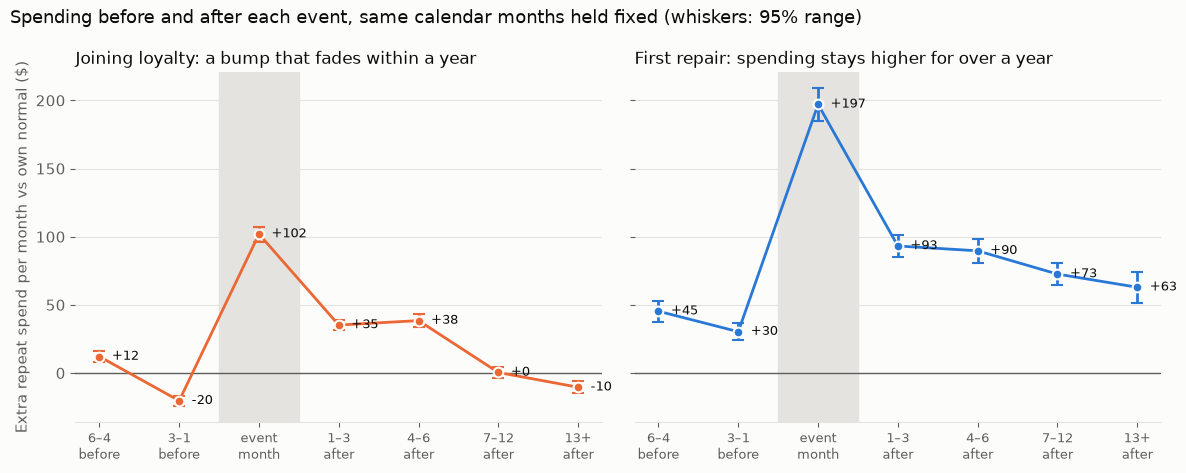

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
e_labs = [b[2] for b in E_BINS]
e_xs = np.arange(len(e_labs))
for ax, (prog, colr, ttl) in zip(axes, [("Loyalty", ORANGE, "Joining loyalty: a bump that fades within a year"),
                                        ("Repairs", BLUE, "First repair: spending stays higher for over a year")]):
    d = event.loc[prog].reindex(e_labs)
    ax.axhline(0, color=INK2, lw=1)
    ax.axvspan(1.5, 2.5, color=GRID, zorder=0)
    ax.errorbar(e_xs, d["extra $ per month"], yerr=[d["extra $ per month"] - d["95% low"],
                                                    d["95% high"] - d["extra $ per month"]],
                color=colr, marker="o", ms=7, lw=2, capsize=4, mec="#fcfcfb", mew=1.5)
    for x, v in zip(e_xs, d["extra $ per month"]):
        ax.annotate(f"{v:+.0f}", (x, v), xytext=(9, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_xticks(e_xs, [l.replace(" ", "\n", 1) for l in e_labs], fontsize=9)
    ax.set_title(ttl, loc="left", color=INK, fontsize=12)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Extra repeat spend per month vs own normal ($)")
fig.suptitle("Spending before and after each event, same calendar months held fixed (whiskers: 95% range)",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

**Reading it:** joining loyalty comes with a spending bump that fades within a year, so loyalty mostly brings
spending forward rather than lifting it for good. After a first repair, spending stays above the customer's own
normal for more than a year. Repair users were already spending more before their first repair (self-selection), so
the *shape* is the robust finding and the dollar sizes are not causal. The website term is no larger than its placebo:
no sign the website raised members' spending, and the new manager's effect can't be separated from other store-wide
changes.

## 8. Pilates campaign (Stream D, slide 5)
Customers who signed up during the campaign (Jan 6 – Mar 31, 2025): the 360 from the Pilates campaign vs the 417
from other channels in the **same weeks**, so season and store conditions match. The data has no campaign cost,
so this measures value delivered, not ROI.

In [27]:
cohort = customers[customers["signup_date"].between(C.PILATES_START, C.PILATES_END)].copy()
cohort["group"] = cohort["acquisition_channel"].eq("Pilates Campaign").map(
    {True: "Pilates Campaign", False: "Other channels, same weeks"})

pv = visits.merge(cohort[["customer_id", "group"]], on="customer_id")
pv["days"] = (pv["date"] - pv["signup_date"]).dt.days
for d in [90, 180, 365]:
    cohort[f"came_back_{d}d"] = cohort["customer_id"].isin(pv.loc[pv["days"].between(1, d), "customer_id"])
cohort["one_visit_only"] = cohort["n_visits"] == 1
cohort["last_visit_in_campaign"] = cohort["last_visit"] <= C.PILATES_END

first_year = (pv[pv["days"] <= 365].groupby(["customer_id", "group"])
              .agg(revenue=("revenue", "sum"), profit=("profit", "sum")).reset_index())
pilates = pd.concat([
    cohort.groupby("group")[["came_back_90d", "came_back_180d", "came_back_365d", "one_visit_only",
                             "last_visit_in_campaign", "churned"]].mean().mul(100).round(1),
    first_year.groupby("group")[["revenue", "profit"]].mean().round(0).add_prefix("first_year_").add_suffix("_per_customer"),
    cohort.groupby("group")["arr_12m"].mean().round(0).rename("arr_now_per_customer"),
], axis=1)
pilates.T

group,"Other channels, same weeks",Pilates Campaign
came_back_90d,53.7,43.3
came_back_180d,69.8,50.0
came_back_365d,80.6,52.2
one_visit_only,16.8,46.9
last_visit_in_campaign,23.0,63.9
churned,59.5,90.3
first_year_revenue_per_customer,842.0,368.0
first_year_profit_per_customer,496.0,226.0
arr_now_per_customer,591.0,148.0


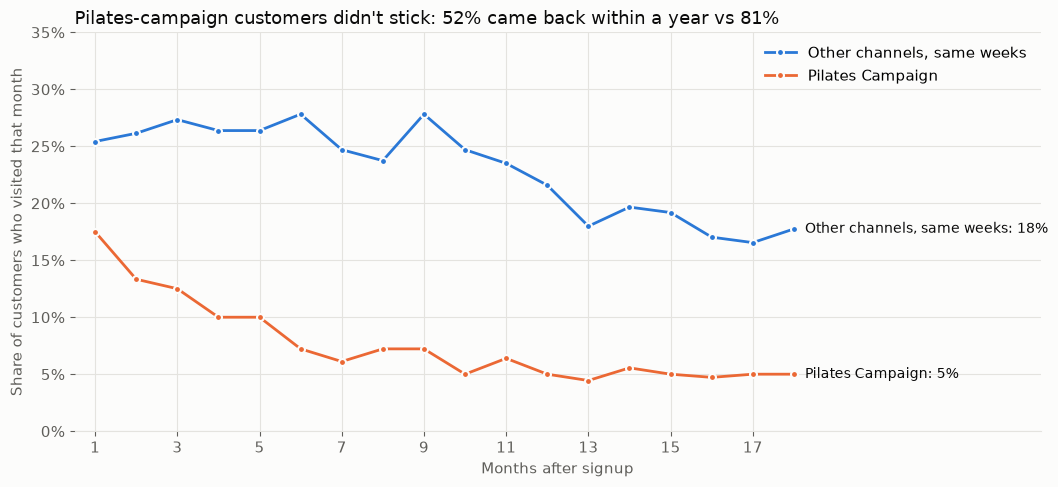

In [28]:
pv["month_after"] = pv["days"] // 30
curve = (pv[pv["month_after"].between(1, 18)].groupby(["group", "month_after"])["customer_id"].nunique()
         .unstack(0).div(cohort.groupby("group").size()) * 100)

fig, ax = plt.subplots(figsize=(11, 5))
for name, colr in [("Other channels, same weeks", BLUE), ("Pilates Campaign", ORANGE)]:
    ax.plot(curve.index, curve[name], color=colr, label=name, marker="o", ms=5, mec="#fcfcfb", mew=1.5)
    ax.annotate(f"{name}: {curve[name].iloc[-1]:.0f}%", (curve.index[-1], curve[name].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.set_xlim(0.5, 24)
ax.set_xticks(range(1, 19, 2))
ax.set_ylim(0, 35)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Months after signup")
ax.set_ylabel("Share of customers who visited that month")
ax.legend(loc="upper right", frameon=False)
p, o = pilates.loc["Pilates Campaign"], pilates.loc["Other channels, same weeks"]
ax.set_title(f"Pilates-campaign customers didn't stick: {p['came_back_365d']:.0f}% came back within a year "
             f"vs {o['came_back_365d']:.0f}%", loc="left", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

## 9. Checking the evidence behind the price and points proposals (Stream D, slide 9)
Full notebook: `analysis/d_customers_arr/d7_recommendation_checks.ipynb`.

**(a) Would a leggings discount win back 18–24s?** In the year before the competitor (Mar 2023 – Feb 2024): the
share of each age group's spending made at sale prices (Black Friday, Boxing Week), and the share spent on leggings.
Then the yearly cost of a storewide leggings discount (last 12 months of leggings sales × discount), against the
most that winning back half the lost young shoppers is worth.

**What winning back young shoppers is worth.** Compare 18–24 buyers in the year before the competitor (Mar 2023 –
Feb 2024) with the latest 12 months (Nov 2025 – Oct 2026). Three ways to value winning back **half** of what was lost,
each before the cost of any offer: (1) lost buyers × today's profit per young buyer (the headline, upper end);
(2) lost 18–24 revenue × today's 18–24 margin; (3) lost 18–24 ARR (Feb 2024 → Oct 2026) × today's margin. The range
runs from the lowest to the highest of the three.

In [29]:
def r_year(start, end):
    w = visits[(visits["date"] >= start) & (visits["date"] < end)
               & (visits["customer_id"].map(c_cust["age_band"]) == "18-24")]
    buyers = w.loc[w["has_purchase"], "customer_id"].nunique()
    return pd.Series({"revenue": w["revenue"].sum(), "profit": w["profit"].sum(), "buyers": buyers,
                      "profit per buyer": w["profit"].sum() / buyers})


r_young = pd.DataFrame({"Year before competitor (Mar 2023 – Feb 2024)": r_year("2023-03-01", "2024-03-01"),
                        "Latest 12 months (Nov 2025 – Oct 2026)": r_year("2025-11-01", "2026-11-01")}).T
r_then, r_now = r_young.iloc[0], r_young.iloc[1]
r_margin_now = r_now["profit"] / r_now["revenue"]
r_arr_young = customer_month[customer_month["customer_id"].map(c_cust["age_band"]) == "18-24"].groupby("month")["arr_12m"].sum()
r_lost_arr = r_arr_young[pd.Timestamp("2024-02-01")] - r_arr_young[pd.Timestamp("2026-10-01")]
r_win = pd.Series({
    "(1) lost buyers × today's profit per buyer × 50%": (r_then["buyers"] - r_now["buyers"]) * r_now["profit per buyer"] * 0.5,
    "(2) lost revenue × today's margin × 50%": (r_then["revenue"] - r_now["revenue"]) * r_margin_now * 0.5,
    "(3) lost ARR × today's margin × 50%": r_lost_arr * r_margin_now * 0.5,
}, name="profit a year ($)")
R_WIN_BACK_LOW, R_WIN_BACK_HIGH, R_PER_SHOPPER = r_win.min(), r_win.max(), r_now["profit per buyer"]
print(f"Lost 18–24 buyers: {r_then['buyers'] - r_now['buyers']:,.0f} · profit per young buyer today: ${R_PER_SHOPPER:,.0f} · "
      f"18–24 margin today: {r_margin_now:.1%} · lost 18–24 ARR: ${r_lost_arr:,.0f}")
print(f"Win back half the lost young shoppers: ${R_WIN_BACK_LOW / 1e3:,.0f}K to ${R_WIN_BACK_HIGH / 1e3:,.0f}K profit a year, "
      "before the cost of the offer")
display(r_young.round(0))
r_win.round(0)

Lost 18–24 buyers: 912 · profit per young buyer today: $429 · 18–24 margin today: 56.1% · lost 18–24 ARR: $549,382
Win back half the lost young shoppers: $154K to $195K profit a year, before the cost of the offer


,revenue,profit,buyers,profit per buyer
Year before competitor (Mar 2023 – Feb 2024),1270206.0,804410.0,1799.0,447.0
Latest 12 months (Nov 2025 – Oct 2026),677758.0,380130.0,887.0,429.0


(1) lost buyers × today's profit per buyer × 50%    195422.0
(2) lost revenue × today's margin × 50%             166141.0
(3) lost ARR × today's margin × 50%                 154064.0
Name: profit a year ($), dtype: float64

In [30]:
r_buys = lines[lines["row_type"] == C.PURCHASE].copy()
r_buys["on_sale"] = r_buys["unit_price_paid"] < r_buys["price"] - 0.005
r_pre = r_buys[(r_buys["date"] >= "2023-03-01") & (r_buys["date"] < "2024-03-01")]
r_sens = pd.DataFrame({
    "% of spend at sale prices": r_pre[r_pre["on_sale"]].groupby("age_band")["revenue"].sum()
                                 / r_pre.groupby("age_band")["revenue"].sum() * 100,
    "% of spend on leggings": r_pre[r_pre["category"] == "Leggings"].groupby("age_band")["revenue"].sum()
                              / r_pre.groupby("age_band")["revenue"].sum() * 100,
}).loc[A_AGES].round(1)
display(r_sens)

r_lg = r_buys[(r_buys["category"] == "Leggings") & (r_buys["date"] > C.DATA_END - pd.Timedelta(days=365))]
r_lg_rev = r_lg["revenue"].sum()
r_lg_cost = (r_lg["quantity"] * r_lg["production_cost"]).sum()
r_price = pd.DataFrame({f"{d:.0%} off all leggings": {
    "yearly cost ($K)": r_lg_rev * d / 1e3,
    "leggings margin after (%)": (r_lg_rev * (1 - d) - r_lg_cost) / (r_lg_rev * (1 - d)) * 100,
    "young shoppers won back to break even": r_lg_rev * d / R_PER_SHOPPER,
    f"cost vs max win-back value (${R_WIN_BACK_HIGH / 1e3:,.0f}K)": "below" if r_lg_rev * d < R_WIN_BACK_HIGH else "above",
} for d in [0.10, 0.15, 0.20]}).T
print(f"Leggings, last 12 months: ${r_lg_rev:,.0f} of sales, margin {(r_lg_rev - r_lg_cost) / r_lg_rev:.0%}. "
      f"18–24 share of leggings sales: {r_lg.loc[r_lg['age_band'] == '18-24', 'revenue'].sum() / r_lg_rev:.0%}")
r_price

,% of spend at sale prices,% of spend on leggings
age_band,,
18-24,5.0,22.8
25-34,5.5,23.0
35-44,5.3,22.8
45-54,5.2,24.2
55+,4.6,23.6


Leggings, last 12 months: $1,339,216 of sales, margin 62%. 18–24 share of leggings sales: 8%


,yearly cost ($K),leggings margin after (%),young shoppers won back to break even,cost vs max win-back value ($195K)
10% off all leggings,133.9216,57.593763,312.493891,below
15% off all leggings,200.8824,55.099278,468.740837,above
20% off all leggings,267.8432,52.292983,624.987783,above


Young shoppers bought on sale no more than other ages, and they are a small share of today's leggings sales, so most
of a storewide discount would go to customers who already buy at full price. A 10% discount costs most of the
win-back value and 15% already costs more than its upper end. **So the recommendation is a targeted test, not a
storewide price match:** an 18–24 leggings/basics offer in selected weeks or for a test group of customers, scaled
up only if the extra profit from returning young shoppers beats the cost of the offer.

**(b) A 50% cap on paying with points.** Last 12 months, purchases only: how many purchases were paid more than half
with points, how many points sit above that cap, and how often those purchases are returned. A cap doesn't destroy
points (customers keep them for later), so it **delays** redemption rather than lowering total loyalty cost. Its
job is to cut points-funded returns.

In [31]:
r_pt = (lines[lines["row_type"] == C.PURCHASE].groupby("transaction_id")["revenue"].sum().to_frame("revenue")
        .join(visits.set_index("transaction_id")[["redeemed_dollars", "date"]]))
r_pt = r_pt[(r_pt["revenue"] > 0) & (r_pt["date"] > C.DATA_END - pd.Timedelta(days=365))]
r_pt["share"] = (r_pt["redeemed_dollars"] / r_pt["revenue"]).clip(upper=1)
r_pt["returned"] = r_pt.index.isin(set(lines.loc[lines["row_type"] == "Return", "original_transaction_id"].dropna()))
r_over = r_pt["share"] > 0.5
pd.Series({
    "purchases in the last 12 months": len(r_pt),
    "purchases paid more than half with points": int(r_over.sum()),
    "share of purchases over the cap (%)": r_over.mean() * 100,
    "points redeemed, total ($)": r_pt["redeemed_dollars"].sum(),
    "points above the cap ($)": (r_pt.loc[r_over, "redeemed_dollars"] - 0.5 * r_pt.loc[r_over, "revenue"]).sum(),
    "return rate, over the cap (%)": r_pt.loc[r_over, "returned"].mean() * 100,
    "return rate, other points purchases (%)": r_pt.loc[~r_over & (r_pt["share"] > 0), "returned"].mean() * 100,
}).round(1)

purchases in the last 12 months               46347.0
purchases paid more than half with points      1982.0
share of purchases over the cap (%)               4.3
points redeemed, total ($)                   412885.0
points above the cap ($)                      29132.1
return rate, over the cap (%)                    23.7
return rate, other points purchases (%)          10.3
dtype: float64

**What this supports:** refunding redeemed points *as points* on returns is strongly supported (today a return refunds the
full price but the redeemed points are never given back, about $70K of points-paid value since launch; the store's
refund policy is unconfirmed). The 50% cap is worth **testing** to reduce
points-funded returns, but it won't lower the structural cost of points. To lower that cost, test the **earn rate**
(each 0.25 pts per $ ≈ $81K a year) or the **Gold-tier threshold** (Gold is 69% of member spend).

### Headline numbers quoted on the slides
The remaining figures on the main slides, each computed from the tables above.
- **ARR:** Feb 2024 (the last full month before the competitor) vs Oct 2026, for everyone and for 18–24s.
- **Returning customers, visits and spend per visit:** repeat purchase visits in the year before the competitor
  (Mar 2023 – Feb 2024) vs the last 12 months (Nov 2025 – Oct 2026). Twelve-month windows, so seasons cancel.
  Purchase visits only (repair trips bring in $0 and didn't exist before April 2025).
- **Points:** redeemed in the last 12 months; what bringing redemptions back to 5% of sales would save if members
  kept spending the same (the upper end; $0 if they cut spending in step); the cost of each extra 0.25 points per
  dollar on members' net sales (after returns); points still unredeemed; Gold's share of member spending (first and last full quarters).
- **Repair users:** share who have reached Gold, among customers with ARR today.

In [32]:
h_arr = customer_month.groupby("month")["arr_12m"].sum()
h_feb24, h_oct26 = pd.Timestamp("2024-02-01"), pd.Timestamp("2026-10-01")

h_rv = visits[visits["is_repeat_visit"] & visits["has_purchase"]]


def h_window(a, b):
    w = h_rv[(h_rv["date"] >= a) & (h_rv["date"] < b)]
    return pd.Series({"customers": w["customer_id"].nunique(), "visits": len(w), "revenue": w["revenue"].sum()})


h_pre, h_now = h_window("2023-03-01", "2024-03-01"), h_window("2025-11-01", "2026-11-01")

h_last12 = visits[visits["date"] > C.DATA_END - pd.Timedelta(days=365)]
h_redeemed, h_rev12 = h_last12["redeemed_dollars"].sum(), h_last12["revenue"].sum()
h_member_sales = h_last12.loc[h_last12["tier"].isin(["Member", "Silver", "Gold"]), "revenue"].sum()   # net of returns
h_balance = (lines[lines["tier_at_purchase"].isin(["Member", "Silver", "Gold"])].sort_values("datetime")
             .groupby("customer_id")["points_balance_after"].last().sum() / C.POINTS_PER_DOLLAR_REDEEMED)
h_mem = visits[visits["tier"].isin(["Member", "Silver", "Gold"])]
h_gold = (h_mem[h_mem["tier"] == "Gold"].groupby(h_mem["date"].dt.to_period("Q"))["revenue"].sum()
          / h_mem.groupby(h_mem["date"].dt.to_period("Q"))["revenue"].sum() * 100)
h_arr_now = customers[customers["arr_12m"] > 0]
h_gold_rep = h_arr_now.groupby("used_repair")["max_tier"].apply(lambda s: (s == "Gold").mean() * 100)

pd.Series({
    "ARR Feb 2024 ($M)": h_arr[h_feb24] / 1e6,
    "ARR Oct 2026 ($M)": h_arr[h_oct26] / 1e6,
    "ARR change, Feb 2024 → Oct 2026 (%)": (h_arr[h_oct26] / h_arr[h_feb24] - 1) * 100,
    "18–24 ARR change, Feb 2024 → Oct 2026 (%)": (r_arr_young[h_oct26] / r_arr_young[h_feb24] - 1) * 100,
    "returning customers, last 12 months vs year before competitor (%)": (h_now["customers"] / h_pre["customers"] - 1) * 100,
    "purchase visits per returning customer (%)": ((h_now["visits"] / h_now["customers"])
                                                   / (h_pre["visits"] / h_pre["customers"]) - 1) * 100,
    "spend per visit (%)": ((h_now["revenue"] / h_now["visits"]) / (h_pre["revenue"] / h_pre["visits"]) - 1) * 100,
    "points redeemed, last 12 months ($K)": h_redeemed / 1e3,
    "points redeemed, % of sales, last 12 months": h_redeemed / h_rev12 * 100,
    "saving if points went back to 5% of sales, upper end ($K)": (h_redeemed - 0.05 * h_rev12) / 1e3,
    "cost of each extra 0.25 points per $ on members' net sales ($K a year)":
        h_member_sales * 0.25 / C.POINTS_PER_DOLLAR_REDEEMED / 1e3,
    "points still unredeemed ($K)": h_balance / 1e3,
    f"Gold share of member spending, {h_gold.index[1]} (%)": h_gold.iloc[1],
    f"Gold share of member spending, {h_gold.index[-2]} (%)": h_gold.iloc[-2],
    "repair users with ARR who reached Gold (%)": h_gold_rep[True],
    "other customers with ARR who reached Gold (%)": h_gold_rep[False],
}).round(1)

ARR Feb 2024 ($M)                                                           6.3
ARR Oct 2026 ($M)                                                           6.7
ARR change, Feb 2024 → Oct 2026 (%)                                         6.0
18–24 ARR change, Feb 2024 → Oct 2026 (%)                                 -46.1
returning customers, last 12 months vs year before competitor (%)         -18.3
purchase visits per returning customer (%)                                 33.5
spend per visit (%)                                                        -2.4
points redeemed, last 12 months ($K)                                      412.9
points redeemed, % of sales, last 12 months                                 5.9
saving if points went back to 5% of sales, upper end ($K)                  61.9
cost of each extra 0.25 points per $ on members' net sales ($K a year)     81.3
points still unredeemed ($K)                                              126.6
Gold share of member spending, 2024Q3 (%

## 10. Recommendation, KPIs & risks (Stream D, slides 9-10)
**Answer:** not as planned. Revenue recovered from fewer, older customers spending more (sections 3–4), so the
gap is keeping customers, not rewarding the ones who stay. **Keep free repairs:** repair users stop shopping about
16 points less often than similar customers (5–9 points after model controls), closing them is about break-even on
profit (central estimates −$67K and +$55K a year; 90% range about −$123K to +$83K, section 6), their spending stays
higher for over a year (section 7), and they don't cannibalize outerwear. **Don't expand loyalty as it stands:**
members spend more, but mostly because the best customers join; no separate retention effect is detected, the
joining bump fades within a year, points cost a steady ~6% of revenue (set by tier mix: Gold is 69% of member
spend), and heavy-points purchases are returned 2.4× as often (section 5). **Win back young shoppers with a targeted
test, not a storewide price match** (section 9).

In [33]:
since_launch = visits[visits["date"] >= C.LOYALTY_LAUNCH]
pd.Series({
    "Store profit margin since loyalty launch (%)": since_launch["profit"].sum() / since_launch["revenue"].sum() * 100,
    "Redeemed points since launch ($)": since_launch["redeemed_dollars"].sum(),
    "Redeemed points as share of revenue (%)": since_launch["redeemed_dollars"].sum() / since_launch["revenue"].sum() * 100,
}).round(1)

Store profit margin since loyalty launch (%)        57.0
Redeemed points since launch ($)                796635.0
Redeemed points as share of revenue (%)              5.0
dtype: float64

| Area | Recommendation | KPI to track (target) | Risk to watch |
|---|---|---|---|
| Repairs | Keep free repairs, with a 20-day turnaround target | Churn gap vs similar non-repairers, matched on age, spend and visit frequency (now about 16 pts; break-even 4.6); turnaround ≤ 20 days (over 20 days: 24% churn vs 11–13%) | Some of the gap is self-selection; the churn model puts the true effect near break-even (5–9 pts) |
| Loyalty | Redesign before expanding: reward visits, not just spend; refund redeemed points as points on returns; test a 50% points cap to cut points-funded returns; to lower cost, test the earn rate or Gold threshold | Profit per member after redemptions vs matched non-members; redemptions ≤ 5% of revenue (now 5.9%); return rate of points-paid purchases | Points cost is structural (each +0.25 pts/$ ≈ +$81K/yr); a cap only delays redemption; no separate retention effect detected after controls |
| Acquisition | Judge campaigns on retention, not sign-ups | 6- and 12-month return rate of new customers (Pilates: 52% vs 81%) | Campaign customers churn after the offer ends |
| Customer base | Test a targeted 18–24 leggings/basics offer in selected weeks or customer groups; scale only if incremental profit is positive | New 18–24 customers per quarter; extra profit vs offer cost in the test group | A storewide 10% leggings discount costs ~$134K/yr and 15% (~$201K) exceeds the $195K max win-back value |

**Limitations:** members and repair users choose to take part, so matched comparisons reduce but don't remove
selection bias; ARR lags real changes by up to 12 months; the data has no campaign or program running costs
beyond repairs and redeemed points.

## 11. Appendix: supporting evidence (slides A1–A3)
Every number on the appendix slides is computed here.

**A1 · Loyalty: revenue vs profit.** Customers active in both the 12 months before and after the loyalty launch
(same population as section 5). Members = joined in the first year. Profit per $100 of sales = profit ÷ sales × 100,
where profit already subtracts product cost, repair cost and redeemed points.

In [34]:
ap_cols = ["revenue_pre", "profit_pre", "revenue_post", "profit_post"]
ap_a1 = b.groupby("member")[ap_cols].sum().rename(index={True: "Members", False: "Non-members"})
ap_a1["profit per $100, before"] = ap_a1["profit_pre"] / ap_a1["revenue_pre"] * 100
ap_a1["profit per $100, after"] = ap_a1["profit_post"] / ap_a1["revenue_post"] * 100
ap_a1["change ($ per $100)"] = ap_a1["profit per $100, after"] - ap_a1["profit per $100, before"]
ap_a1["sales change (%)"] = (ap_a1["revenue_post"] / ap_a1["revenue_pre"] - 1) * 100
ap_a1[["revenue_pre", "revenue_post"]] /= 1e6
ap_a1 = ap_a1.rename(columns={"revenue_pre": "sales before ($M)", "revenue_post": "sales after ($M)"})
ap_a1.drop(columns=["profit_pre", "profit_post"]).loc[["Members", "Non-members"]].round(2)

,sales before ($M),sales after ($M),"profit per $100, before","profit per $100, after",change ($ per $100),sales change (%)
member,,,,,,
Members,3.88,4.48,62.75,57.87,-4.88,15.45
Non-members,0.64,0.36,62.73,62.86,0.13,-43.52


**A1 · Basket size vs distance to the next tier.** Member purchase visits after the launch. Points toward the next
tier = points earned in the trailing 365 days (the tier rule in the setup cell); distance = points still needed for
Silver (600) or Gold (2,000). Basket index = the visit's basket as % of that customer's own average basket, so
big and small spenders are compared fairly (100 = their usual).

In [35]:
ap_mv = (lines.assign(gross=lines["revenue"].where(lines["row_type"] == C.PURCHASE, 0),
                      is_buy=lines["row_type"] == C.PURCHASE)
         .groupby("transaction_id").agg(customer_id=("customer_id", "first"), datetime=("datetime", "first"),
                                        join_date=("loyalty_join_date", "first"), points=("points_earned", "sum"),
                                        basket=("gross", "sum"), has_buy=("is_buy", "any")))
ap_mv = ap_mv.sort_values(["customer_id", "datetime"]).reset_index()
ap_mv["trailing"] = (ap_mv.set_index("datetime").groupby("customer_id")["points"]
                     .rolling(f"{C.TIER_WINDOW_DAYS}D", closed="left").sum().fillna(0).values)
ap_m = ap_mv[ap_mv["has_buy"] & ap_mv["join_date"].notna() & (ap_mv["datetime"] >= ap_mv["join_date"])
             & (ap_mv["datetime"] >= C.LOYALTY_LAUNCH)].copy()
ap_m["next_tier"] = np.select([ap_m["trailing"] < C.SILVER_THRESHOLD, ap_m["trailing"] < C.GOLD_THRESHOLD],
                              [f"Member → Silver ({C.SILVER_THRESHOLD} pts)", f"Silver → Gold ({C.GOLD_THRESHOLD:,} pts)"],
                              default="Gold")
ap_m["gap"] = np.where(ap_m["trailing"] < C.SILVER_THRESHOLD, C.SILVER_THRESHOLD - ap_m["trailing"],
                       C.GOLD_THRESHOLD - ap_m["trailing"])
ap_m = ap_m[ap_m["next_tier"] != "Gold"]
ap_m["basket_index"] = ap_m["basket"] / ap_m.groupby("customer_id")["basket"].transform("mean") * 100
AP_GAPS = ["0–50", "50–100", "100–200", "200–400", "400+"]
ap_m["gap_bucket"] = pd.cut(ap_m["gap"], [0, 50, 100, 200, 400, np.inf], labels=AP_GAPS, right=False)
ap_tier = ap_m.groupby(["next_tier", "gap_bucket"], observed=True)["basket_index"].agg(["mean", "size"]).unstack(0)
print(f"{len(ap_m):,} member purchase visits below Gold")
ap_tier.round(1)

44,536 member purchase visits below Gold


mean                            \
next_tier  Member → Silver (600 pts) Silver → Gold (2,000 pts)   
gap_bucket                                                       
0–50                            98.2                      97.6   
50–100                         101.6                      97.0   
100–200                        100.6                      98.8   
200–400                         99.4                     109.0   
400+                           101.2                      98.2   

                                size                            
next_tier  Member → Silver (600 pts) Silver → Gold (2,000 pts)  
gap_bucket                                                      
0–50                            1084                       492  
50–100                          1248                       485  
100–200                         2792                      1030  
200–400                         6370                      2104  
400+                           13126                     15805

**A2 · Categories and seasons.** (a) Sales by category, March–October 2026 vs March–October 2023, for 18–24 year-olds
and shoppers aged 25+ (same months, so seasons don't distort it). (b) Sales by calendar month in the two complete
pre- and post-competitor years, 2023 and 2025 combined, as an index (average month = 100), with each month's margin.

In [36]:
ap_p = a_p[a_p["mon"].between(3, 10) & a_p["year"].isin([2023, 2026])]
ap_p = ap_p.assign(grp=np.where(ap_p["age_band"] == "18-24", "Aged 18–24", "Aged 25+"))
ap_cat = ap_p.groupby(["category", "grp", "year"])["revenue"].sum().unstack("year")
ap_cat = ((ap_cat[2026] / ap_cat[2023] - 1) * 100).unstack("grp").sort_values("Aged 18–24")

ap_v = visits[visits["date"].dt.year.isin([2023, 2025])]
ap_month = ap_v.groupby(ap_v["date"].dt.month)[["revenue", "profit"]].sum()
ap_month["index (average month = 100)"] = ap_month["revenue"] / ap_month["revenue"].mean() * 100
ap_month["margin (%)"] = ap_month["profit"] / ap_month["revenue"] * 100
ap_month.index = A_MONTHS
print(f"November + December share of yearly sales: {ap_month.loc[['Nov', 'Dec'], 'revenue'].sum() / ap_month['revenue'].sum():.1%}; "
      f"December margin {ap_month.loc['Dec', 'margin (%)']:.0f}% vs {ap_month.loc['Jan':'Sep', 'margin (%)'].mean():.0f}% in Jan–Sep")
display(ap_cat.round(1))
ap_month[["index (average month = 100)", "margin (%)"]].round(1).T

November + December share of yearly sales: 27.3%; December margin 56% vs 61% in Jan–Sep


grp,Aged 18–24,Aged 25+
category,,
Leggings,-63.5,-4.0
Outerwear,-53.1,0.2
Hoodies & Sweaters,-45.4,41.8
Tank Tops,-43.7,41.3
Shorts,-38.7,40.2
Accessories,-38.6,39.3
Tops,-38.3,41.1
Sports Bras,-37.9,38.9


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
index (average month = 100),91.6,72.6,87.4,82.4,87.1,77.6,79.9,85.0,105.3,103.6,131.0,196.5
margin (%),61.0,60.9,61.0,60.5,60.7,60.8,61.2,60.9,60.4,59.8,57.1,56.0


**A3 · Who brings in our returning-customer sales? (k-means segments, `analysis/d_customers_arr/d8_matching_segments.ipynb`).**
Every customer who made a purchase in the last 12 months, clustered on behaviour only: days since last purchase,
purchase visits, spend, average basket, share paid with points, return rate, years as a customer, repair use and
age (skewed ones log-scaled, all standardised). k = 4: the full notebook compares k = 3–7 by silhouette score; 4 also
separates the frequent returners. Segments are named by rules from their profile, so the names survive a re-run.

In [37]:
from sklearn.cluster import KMeans

ap_y12 = visits[visits["date"] > C.DATA_END - pd.Timedelta(days=365)]
ap_buyers = ap_y12.loc[ap_y12["has_purchase"], "customer_id"].unique()
ap_g = ap_y12[ap_y12["customer_id"].isin(ap_buyers)].groupby("customer_id")
seg = c_cust.loc[ap_buyers].copy()
seg["purchase_visits"] = ap_g["has_purchase"].sum()
seg["spend"] = ap_g["revenue"].sum().clip(lower=0)
seg["avg_basket"] = seg["spend"] / seg["purchase_visits"]
seg["points_share"] = (ap_g["redeemed_dollars"].sum() / ap_g["revenue"].sum().where(lambda s: s > 0)).fillna(0).clip(0, 1)
seg["return_rate"] = ap_g["has_return"].sum() / ap_g.size()
seg["days_since_purchase"] = (C.DATA_END - visits[visits["has_purchase"]].groupby("customer_id")["date"].max()
                              .reindex(seg.index)).dt.days
seg["tenure_years"] = (C.DATA_END - seg["signup_date"]).dt.days / 365
seg["repair_user"] = seg["used_repair"].fillna(False).astype(int)
seg["age_num"] = seg["age_band"].map({"18-24": 21, "25-34": 30, "35-44": 40, "45-54": 50, "55+": 60})
seg["age_num"] = seg["age_num"].fillna(seg["age_num"].median())
AP_FEATS = ["days_since_purchase", "purchase_visits", "spend", "avg_basket", "points_share", "return_rate",
            "tenure_years", "repair_user", "age_num"]
ap_Z = seg[AP_FEATS].astype(float).copy()
for col in ["days_since_purchase", "purchase_visits", "spend", "avg_basket"]:
    ap_Z[col] = np.log1p(ap_Z[col])
seg["segment"] = KMeans(4, n_init=20, random_state=42).fit_predict(StandardScaler().fit_transform(ap_Z))

segments = seg.groupby("segment").agg(
    customers=("spend", "size"), arr=("arr_12m", "sum"), trips_per_year=("purchase_visits", "mean"),
    avg_basket=("avg_basket", "mean"), days_since_purchase=("days_since_purchase", "median"),
    repair_users=("repair_user", "mean"), age_18_24=("age_band", lambda s: (s == "18-24").mean()),
    return_rate=("return_rate", "mean"))
names, left = {}, set(segments.index)
for name, pick in [("Gold regulars", lambda d: d["arr"].idxmax()), ("Frequent returners", lambda d: d["return_rate"].idxmax()),
                   ("Fading light shoppers", lambda d: d["age_18_24"].idxmax())]:
    k = pick(segments.loc[sorted(left)])
    names[k] = name
    left.discard(k)
names[left.pop()] = "Occasional big-basket shoppers"
segments.index = segments.index.map(names)
AP_ORDER = ["Gold regulars", "Occasional big-basket shoppers", "Fading light shoppers", "Frequent returners"]
segments = segments.loc[AP_ORDER]
segments["share of customers (%)"] = segments["customers"] / segments["customers"].sum() * 100
segments["share of ARR (%)"] = segments["arr"] / segments["arr"].sum() * 100
segments["use free repairs (%)"] = segments["repair_users"] * 100
segments[["customers", "share of customers (%)", "share of ARR (%)", "use free repairs (%)", "trips_per_year",
          "avg_basket", "days_since_purchase", "return_rate"]].round(1)

,customers,share of customers (%),share of ARR (%),use free repairs (%),trips_per_year,avg_basket,days_since_purchase,return_rate
segment,,,,,,,,
Gold regulars,1930,31.8,79.7,89.3,18.1,153.4,16.0,0.1
Occasional big-basket shoppers,1913,31.5,14.5,10.0,3.5,199.4,70.0,0.0
Fading light shoppers,1605,26.4,3.2,5.5,1.9,96.8,144.0,0.0
Frequent returners,627,10.3,2.6,13.6,2.8,124.1,125.0,0.3


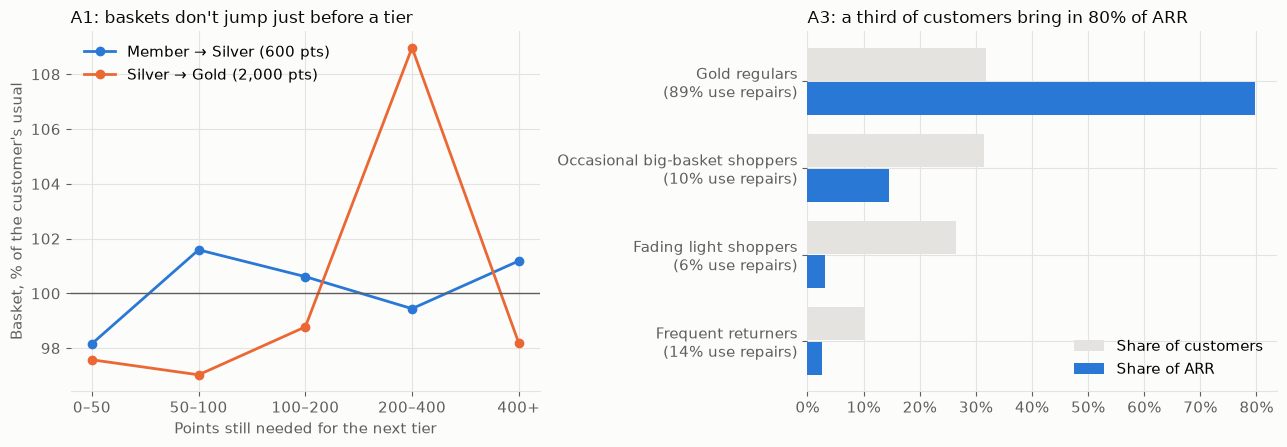

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
x = np.arange(len(AP_GAPS))
for tier, colr in zip(ap_tier["mean"].columns, [BLUE, ORANGE]):
    ax.plot(x, ap_tier["mean"][tier].reindex(AP_GAPS), marker="o", color=colr, label=tier)
ax.axhline(100, color=INK2, lw=1)
ax.set_xticks(x, AP_GAPS)
ax.set_xlabel("Points still needed for the next tier")
ax.set_ylabel("Basket, % of the customer's usual")
ax.legend(frameon=False)
ax.set_title("A1: baskets don't jump just before a tier", loc="left", color=INK, fontsize=12)
ax = axes[1]
y = np.arange(len(segments))
ax.barh(y - 0.2, segments["share of customers (%)"], 0.38, color=GRID, label="Share of customers")
ax.barh(y + 0.2, segments["share of ARR (%)"], 0.38, color=BLUE, label="Share of ARR")
ax.set_yticks(y, [f"{n}\n({r:.0f}% use repairs)" for n, r in segments["use free repairs (%)"].items()])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="lower right")
ax.set_title("A3: a third of customers bring in 80% of ARR", loc="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()